# Nation clustering with socioeconomic indicators

**DS203 code submission - reproducible analysis of 2022 WDI indicators.**

Research question: do economies form interpretable socioeconomic groups, how do those groups compare with external income/region labels, and how do K-means and hierarchical clustering differ?

The main analysis uses all 11 specified numerical indicators. World Bank income group, region and lending type are retained exclusively for interpretation. **2022 indicator values are compared with the metadata snapshot dated 23 November 2026; this is not a historical 2022 classification exercise.**

This notebook extends the supplied teammate baseline. The original raw-GDP result is preserved as a reproducible sensitivity analysis. Only K-means, PCA and the professor-permitted hierarchical method are used. ARI and NMI are descriptive comparison metrics, not additional clustering models.

## How to run

Extract the complete code package, install `requirements.txt`, and open this notebook from the extracted folder. Choose **Restart Kernel and Run All**. All primary analysis runs offline on supplied frozen data. `analysis.py` contains the full editable implementation. Each stage below calls a documented function; exported PNG/PDF charts and CSV tables are recreated.

No report, slides, video or presentation script is included in this code-only submission.


In [1]:
from pathlib import Path
import json
import sys
from IPython.display import display, Image, Markdown
from threadpoolctl import threadpool_limits

ROOT = Path.cwd()
if not (ROOT / 'analysis.py').is_file():
    raise FileNotFoundError('Open the notebook from the extracted DS203_Nation_Clustering folder.')
sys.path.insert(0, str(ROOT))
import analysis as project

def show_figures(*names):
    for name in names:
        display(Image(filename=str(ROOT / 'outputs/figures' / f'{name}.png')))

display(Markdown('### Fixed configuration'))
display(project.CONFIG)


### Fixed configuration

{'year': 2022,
 'missing_fraction_max': 0.5,
 'log_gdp': True,
 'pca_variance_target': 0.8,
 'k_values': [2, 3, 4, 5, 6, 7, 8],
 'random_state': 42,
 'n_init': 50,
 'hierarchical_linkage': 'ward'}

## 1. Source data, country selection and missingness

Source: official World Bank WDI numerical indicators and official World Bank Country API metadata. `data/provenance.json` records URLs, dates, sizes and SHA-256 hashes. The selected year is 2022, retained from the provided baseline for broad coverage and a consistent single-year comparison; we do not assert that it is uniquely optimal.

The bulk CSV is replaced by a small equivalent 11-indicator snapshot. Aggregate entities are removed using metadata, not guessed from names. Country-code merges are validated. Missingness is reported before any deletion or imputation. Economies with more than half the 11 indicators missing are excluded; the remaining missing values are median-imputed globally, without reference labels. A stricter threshold and complete cases are checked later.


In [2]:
state = project.load_data()
display(state['countries'].head())
display(state['coverage'].loc[~state['coverage'].retained])
display(state['countries'][project.FEATURES].isna().sum().sort_values(ascending=False))


DATA AUDIT: {'wdi_entities': 266, 'metadata_economies': 217, 'matched_economies': 217, 'excluded': 12, 'retained': 205, 'complete_cases': 110}
2022 is retained from the supplied project baseline: broad coverage, one common year, no cross-year filling.
Income/region labels describe the metadata snapshot, not historical 2022 classifications.


,Country Name,Country Code,Electricity_Access,Inflation,Internet_Users,Capital_Formation,Trade,GDP_Growth,GDP_PC,Secondary_Enrollment,Unemployment,Life_Expectancy,Urban_Population,Region,IncomeGroup,LendingType
0,Afghanistan,AFG,85.3,13.712102,15.866300,16.700000,72.885470,-6.240172,357.261153,NaN,14.100,65.617,25.393925,"Middle East, North Africa, Afghanistan & Pakistan",Low income,IDA
1,Albania,ALB,100.0,6.725203,82.613675,26.802365,84.698044,4.826801,7756.961887,97.322471,10.785,78.769,57.864348,Europe & Central Asia,Upper middle income,IBRD
2,Algeria,DZA,100.0,9.265516,74.781502,35.097954,51.190089,3.600000,4960.303343,104.550270,12.382,76.129,74.179586,"Middle East, North Africa, Afghanistan & Pakistan",Upper middle income,IBRD
3,American Samoa,ASM,NaN,NaN,NaN,NaN,124.684271,1.735016,18017.458938,NaN,NaN,72.752,81.794798,East Asia & Pacific,High income,Not classified
4,Andorra,AND,100.0,NaN,94.051697,NaN,NaN,9.564612,42414.059011,98.509872,NaN,84.016,88.754877,Europe & Central Asia,High income,Not classified


,Country Code,Country Name,IncomeGroup,Region,LendingType,missing_indicators,missing_fraction,retained,reason
3,ASM,American Samoa,High income,East Asia & Pacific,Not classified,6,0.545455,False,More than 50% of 11 indicators missing
27,VGB,British Virgin Islands,High income,Latin America & Caribbean,Not classified,7,0.636364,False,More than 50% of 11 indicators missing
50,CUW,Curacao,High income,Latin America & Caribbean,Not classified,6,0.545455,False,More than 50% of 11 indicators missing
61,ERI,Eritrea,Low income,Sub-Saharan Africa,IDA,6,0.545455,False,More than 50% of 11 indicators missing
75,GIB,Gibraltar,High income,Europe & Central Asia,Not classified,7,0.636364,False,More than 50% of 11 indicators missing
94,IMN,Isle of Man,High income,Europe & Central Asia,Not classified,6,0.545455,False,More than 50% of 11 indicators missing
103,PRK,"Korea, Dem. People's Rep.",Low income,East Asia & Pacific,Not classified,7,0.636364,False,More than 50% of 11 indicators missing
114,LIE,Liechtenstein,High income,Europe & Central Asia,Not classified,6,0.545455,False,More than 50% of 11 indicators missing
172,SXM,Sint Maarten (Dutch part),High income,Latin America & Caribbean,Not classified,6,0.545455,False,More than 50% of 11 indicators missing
178,SSD,South Sudan,Low income,Sub-Saharan Africa,IDA,6,0.545455,False,More than 50% of 11 indicators missing


Secondary_Enrollment    77
Capital_Formation       42
Inflation               38
Internet_Users          35
Trade                   34
Unemployment            31
GDP_PC                   8
GDP_Growth               8
Electricity_Access       2
Life_Expectancy          0
Urban_Population         0
dtype: int64

## 2. Exploratory analysis on observed data

These plots use observed measurements, before imputation. They cover the required numerical summary, six distributions, four income-group comparisons, correlations and four pairwise relationships. Missing observations produce different sample sizes across indicators; pairwise correlation sample counts are exported.

GDP per capita is strongly right-skewed. Its natural logarithm is assessed explicitly and used in the main model. Raw GDP remains a sensitivity analysis. Other valid extremes are retained: negative growth/inflation are allowed, and trade-to-GDP or gross school enrollment above 100% is not automatically an error.

**Source-quality flag:** the WDI snapshot reports CAF life expectancy as 18.818 years. An independent point-series query returns the same value and a sharp surrounding temporal pattern. It is flagged, retained as source-reported in the main run, and excluded in a separate robustness analysis. No guessed replacement or cross-year fill is introduced. See `DATA_QUALITY.md` and the preserved point-series response.


EDA: six distributions, four income comparisons, four requested scatter plots, correlations and observation counts exported.
Trade/enrollment can exceed 100%; growth and inflation can be negative. Valid extremes are retained.


,count,mean,std,min,25%,50%,75%,max,skewness,missing_percent
GDP_PC,209.0,21200.874,31131.454,301.832,2899.160,7655.594,28360.304,226052.061,3.061,3.687
GDP_Growth,209.0,4.419,6.783,-28.759,2.465,4.253,6.370,63.335,2.223,3.687
Inflation,179.0,12.687,19.669,-6.687,5.551,8.003,12.167,171.205,5.467,17.512
Unemployment,186.0,7.197,5.846,0.130,3.485,5.337,9.194,36.472,1.995,14.286
Trade,183.0,100.405,63.591,2.699,58.787,88.701,123.300,412.177,2.154,15.668
Capital_Formation,175.0,24.415,8.766,-10.596,19.716,24.201,27.764,55.779,0.053,19.355
Life_Expectancy,217.0,73.108,7.941,18.818,67.788,74.211,78.531,85.746,-1.740,0.000
Urban_Population,217.0,62.355,23.329,14.692,42.733,63.307,81.162,100.000,-0.178,0.000
Internet_Users,182.0,70.243,25.270,7.145,56.996,78.781,89.502,100.000,-0.942,16.129
Electricity_Access,215.0,87.492,23.162,8.400,86.500,100.000,100.000,100.000,-1.872,0.922


,Country Code,Country Name,Life_Expectancy,review_flag,main_treatment
37,CAF,Central African Republic,18.818,Source-reported life expectancy below 40 years...,Retained as reported; flagged-economy exclusio...


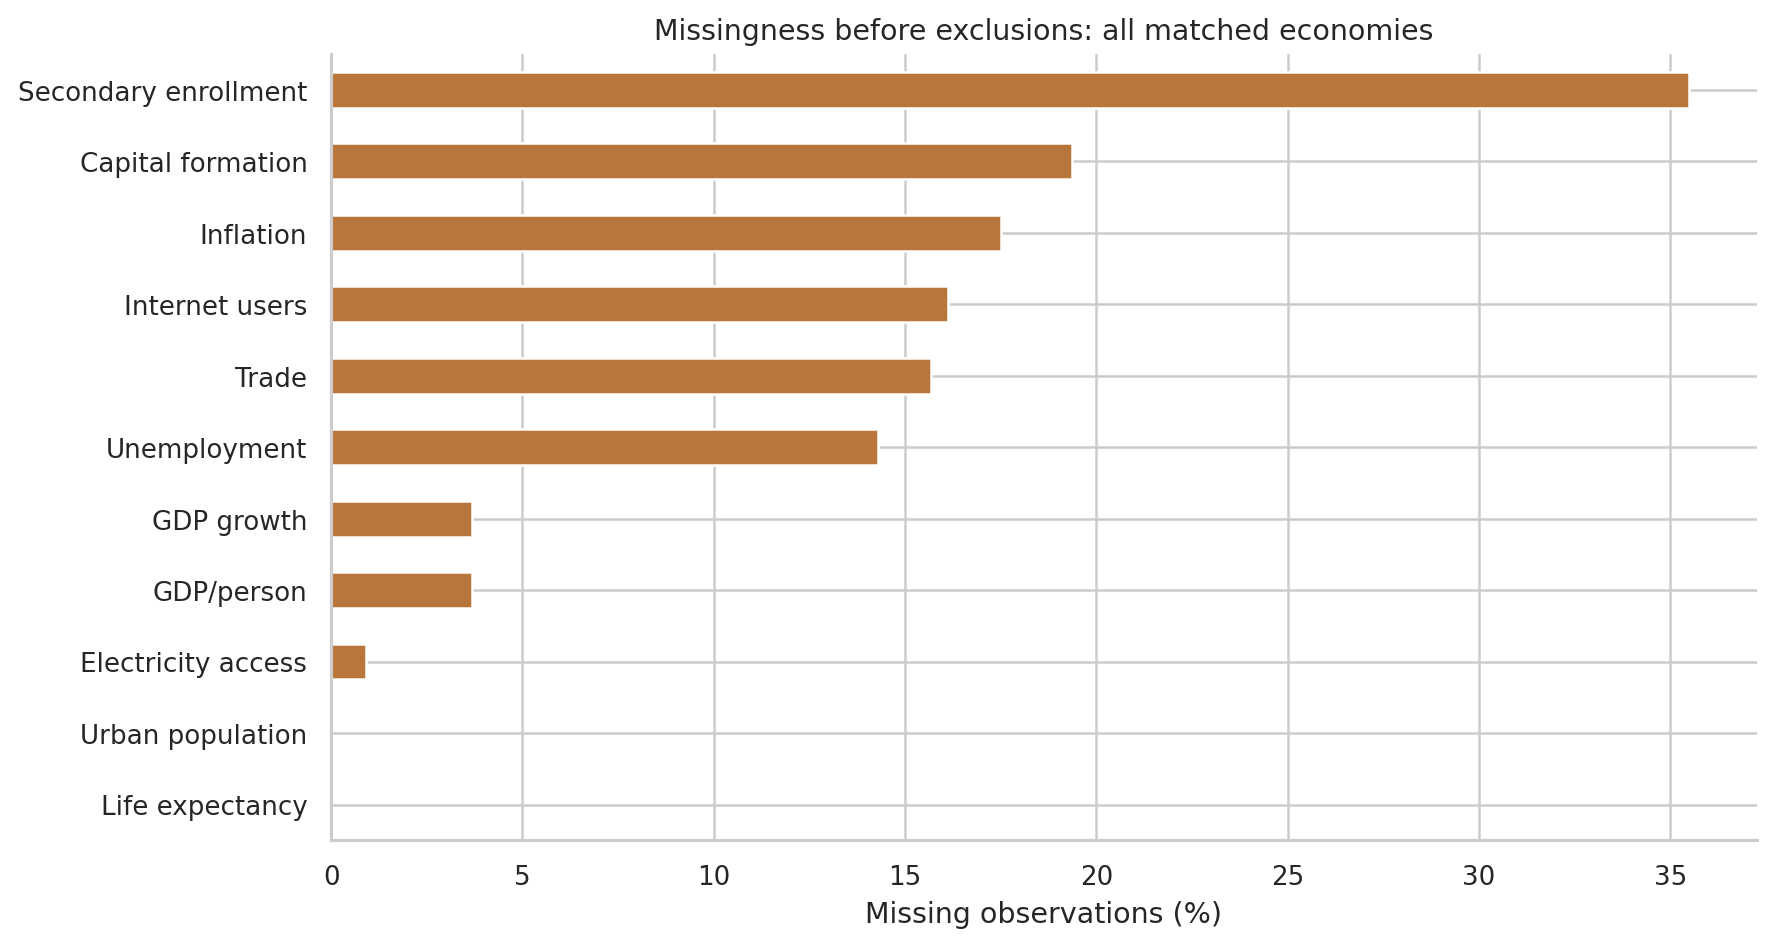

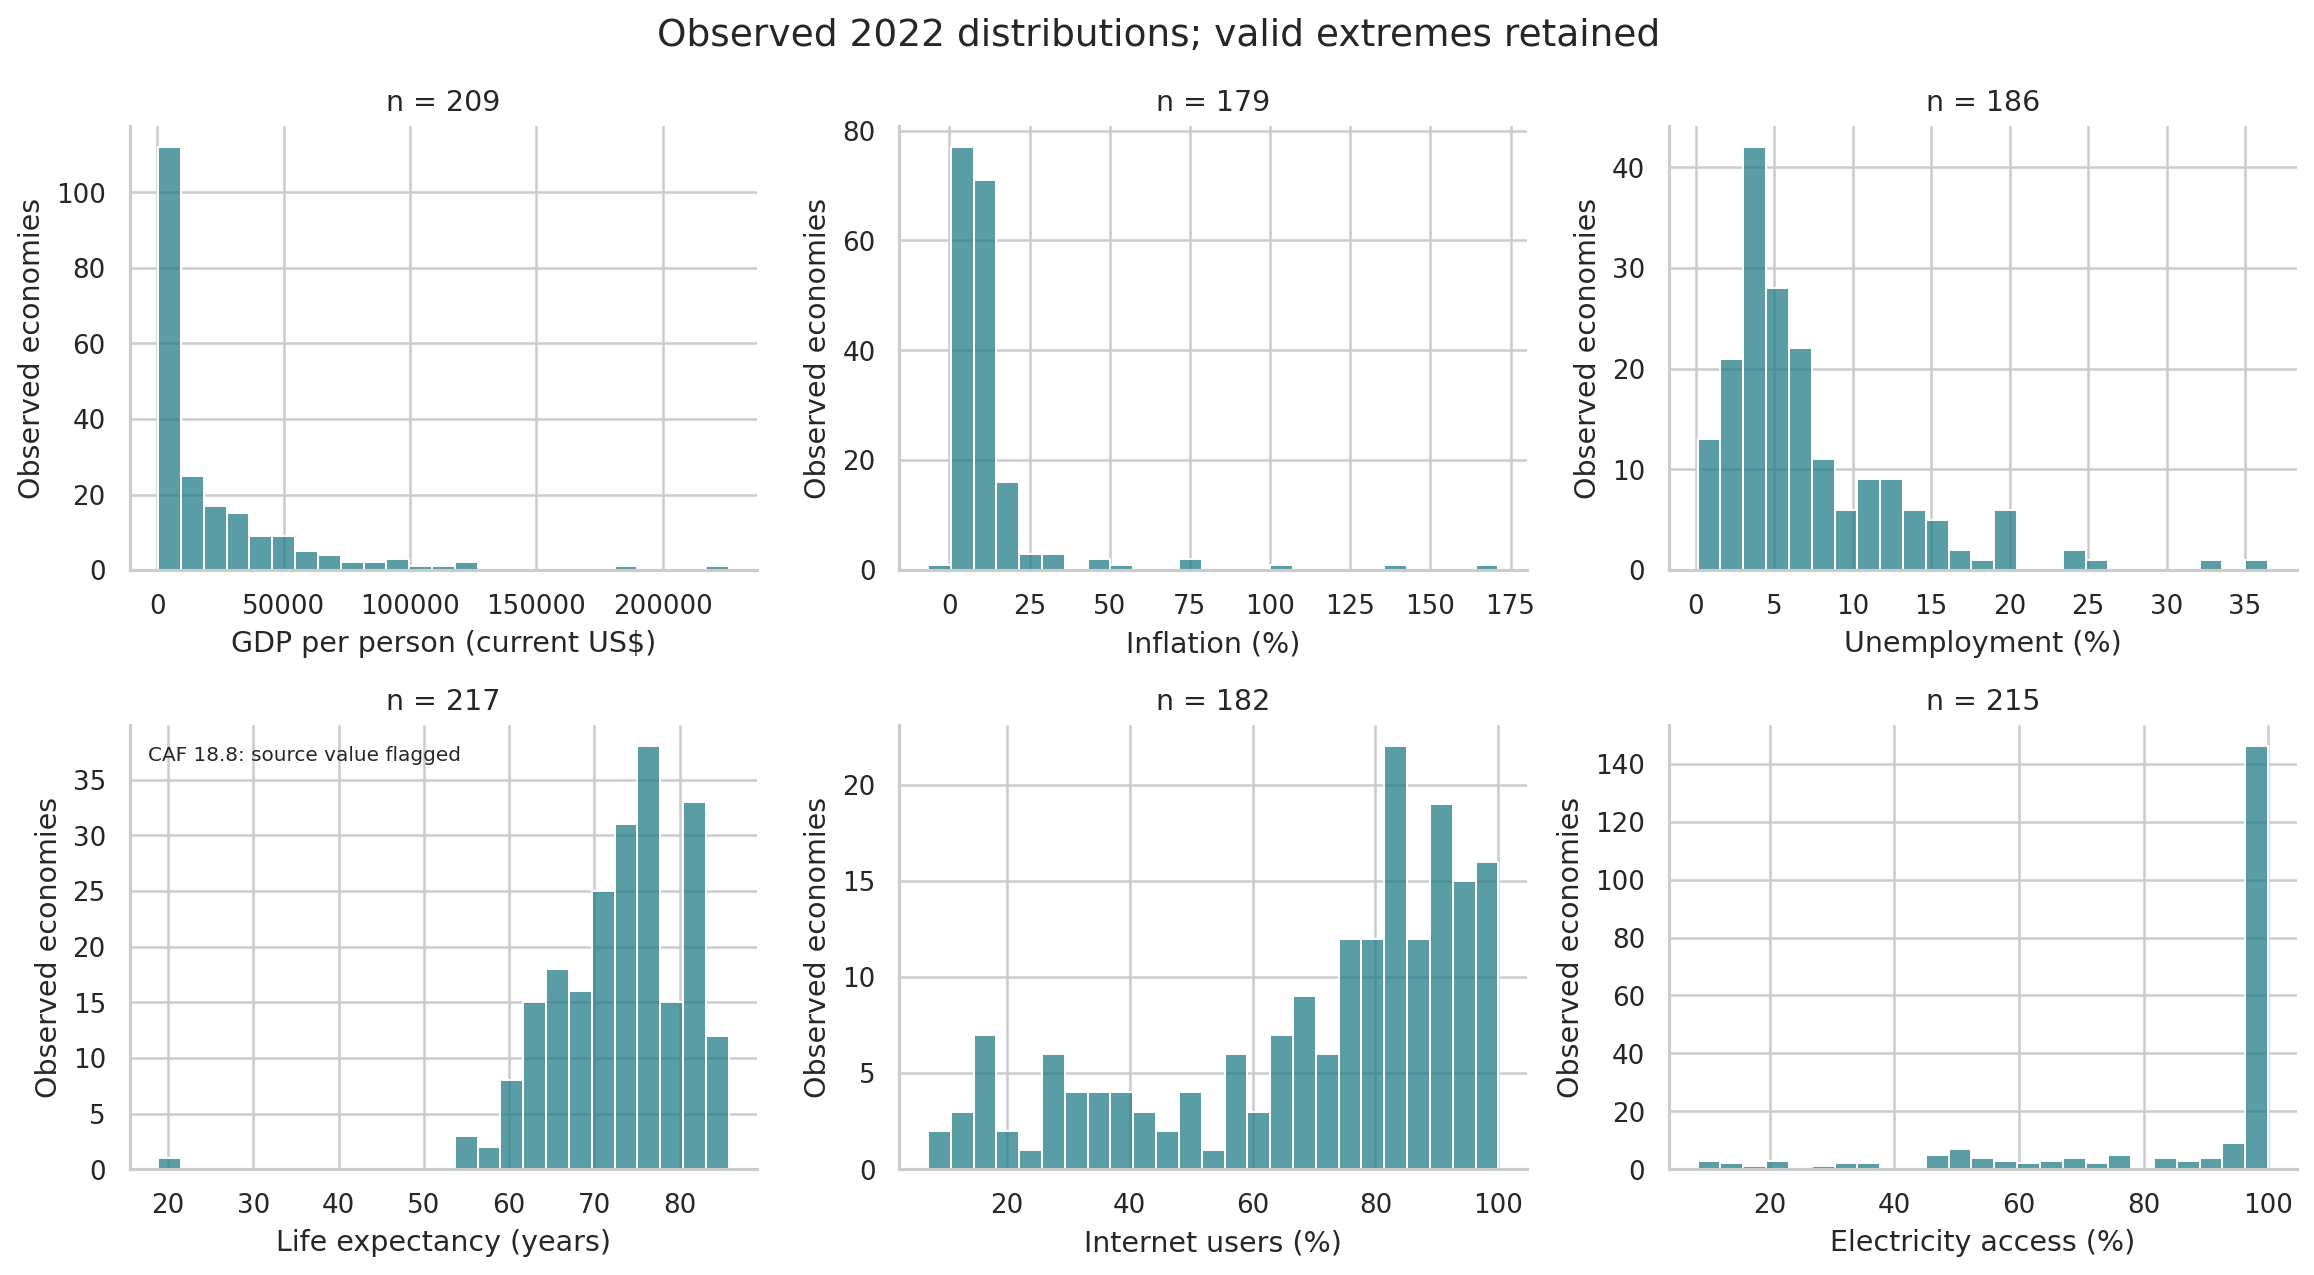

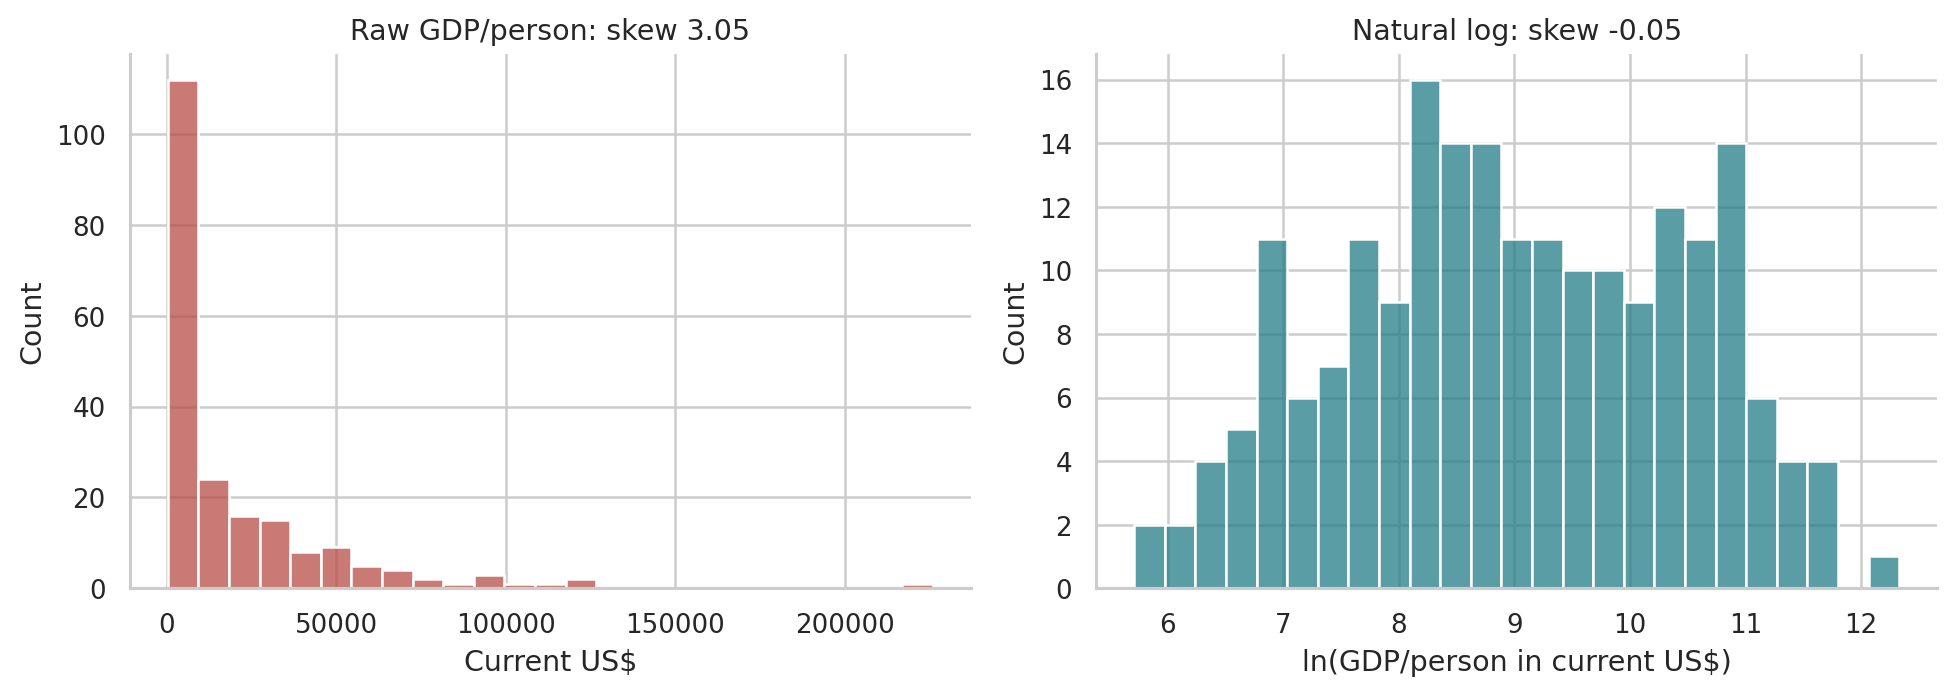

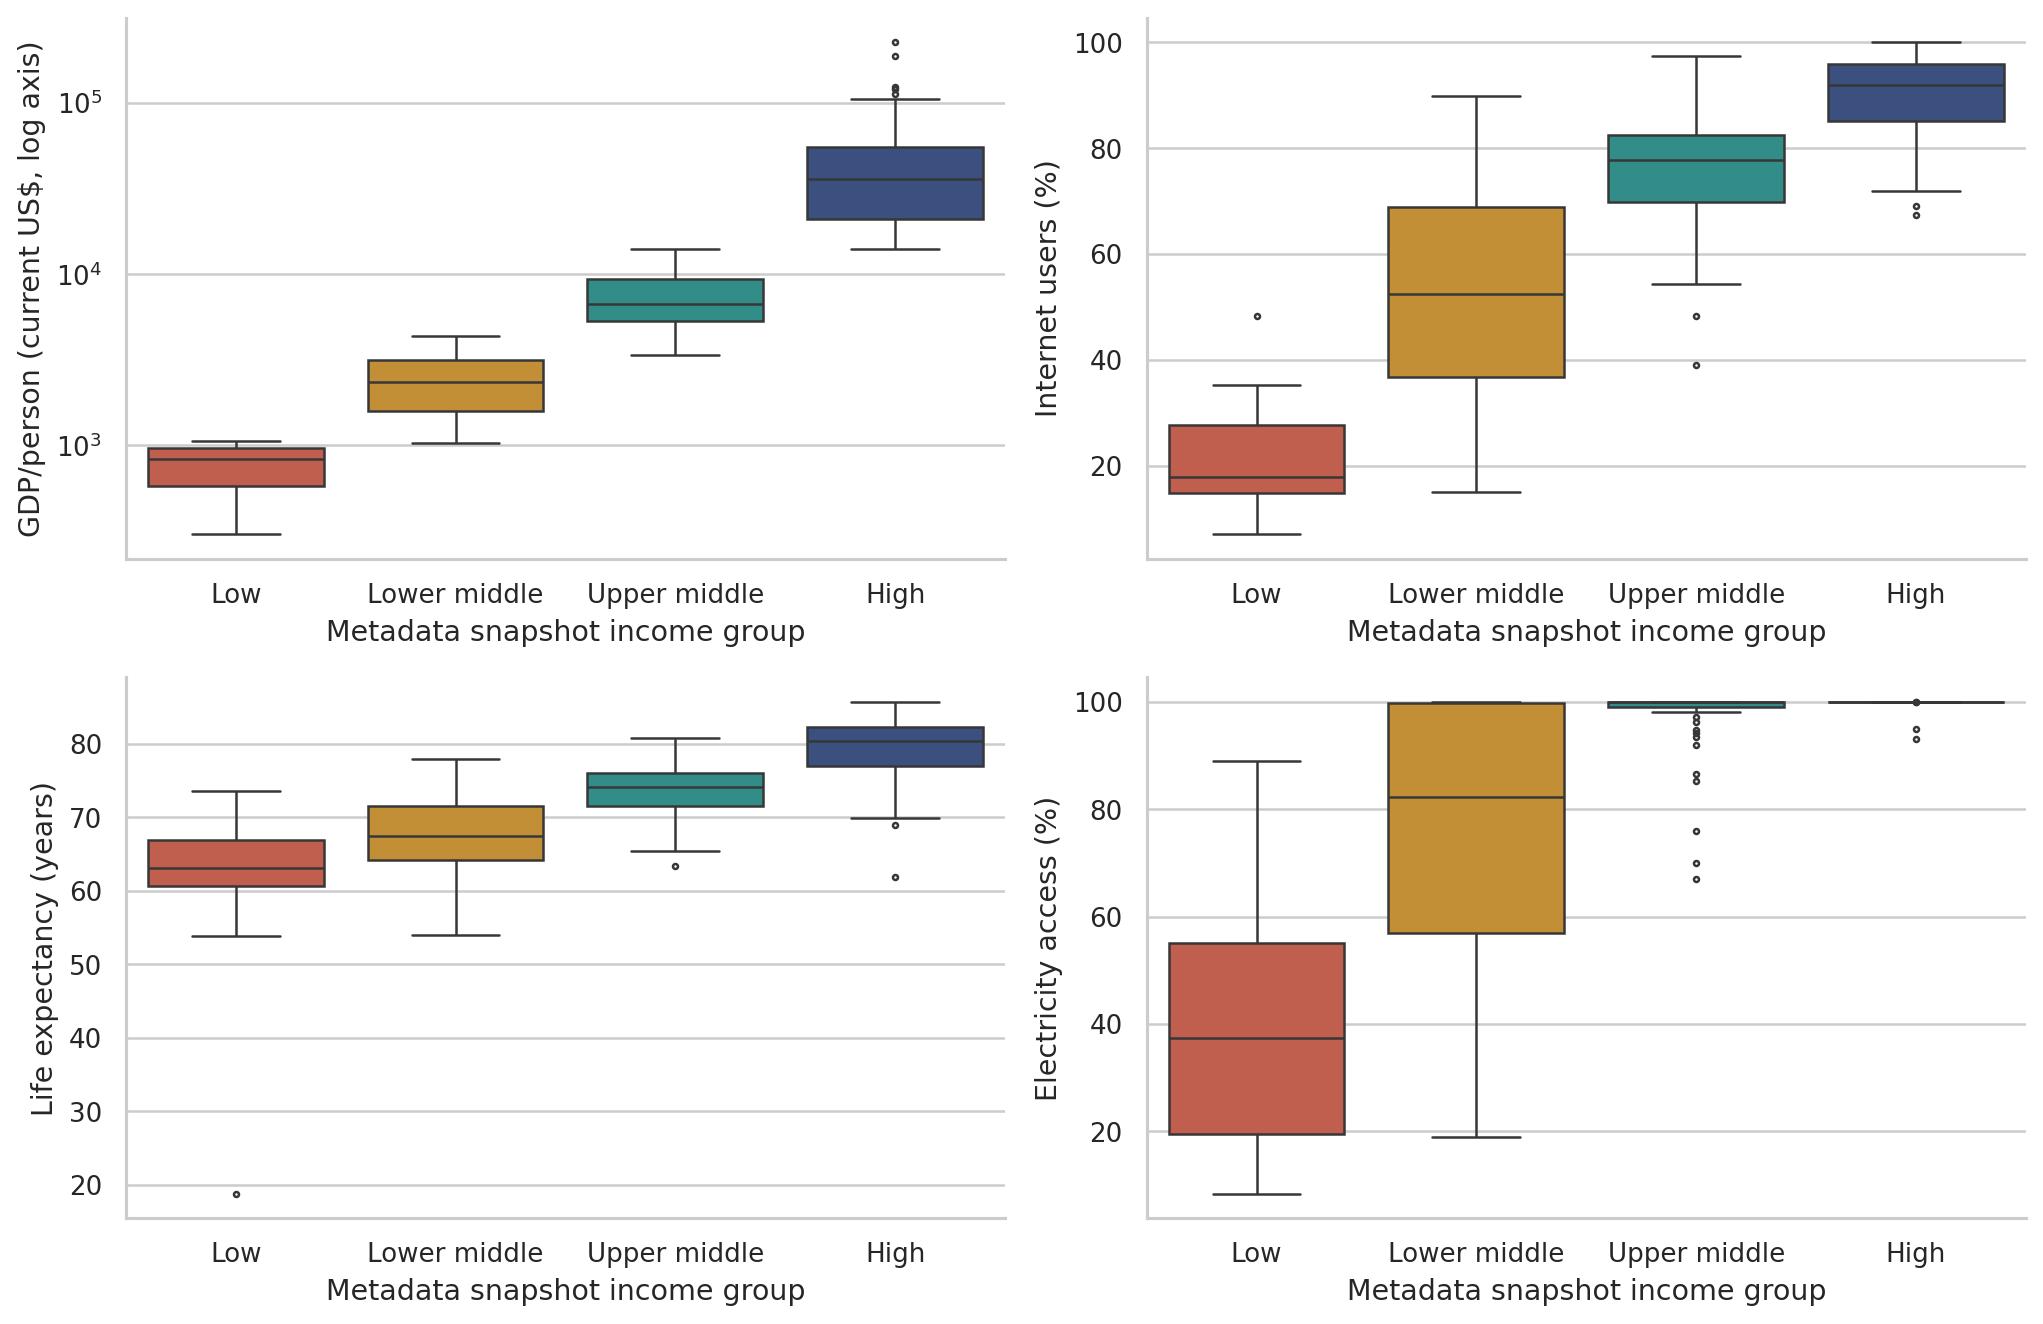

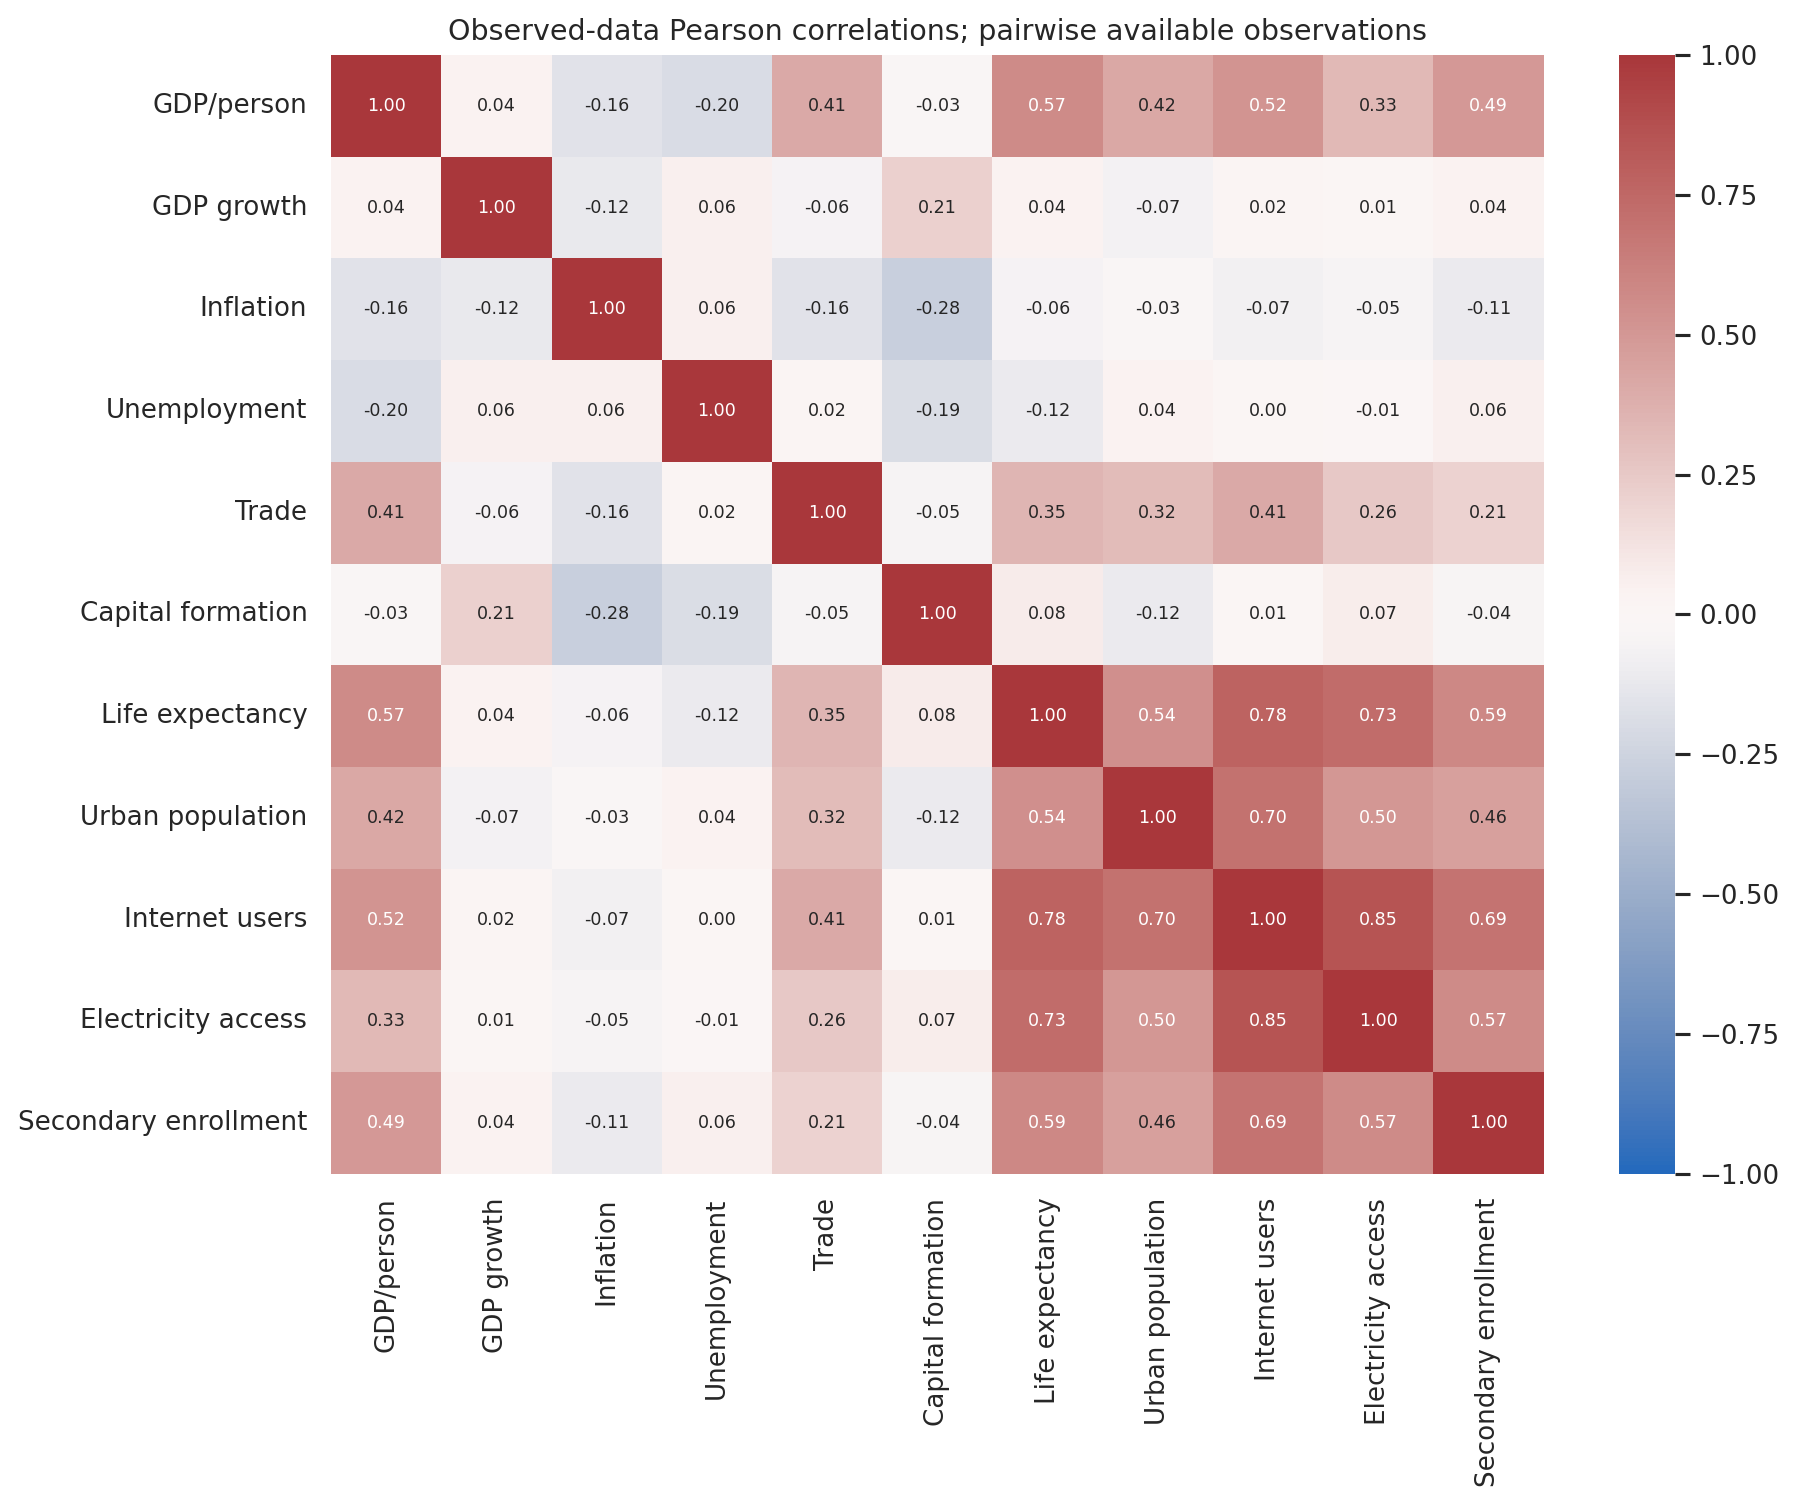

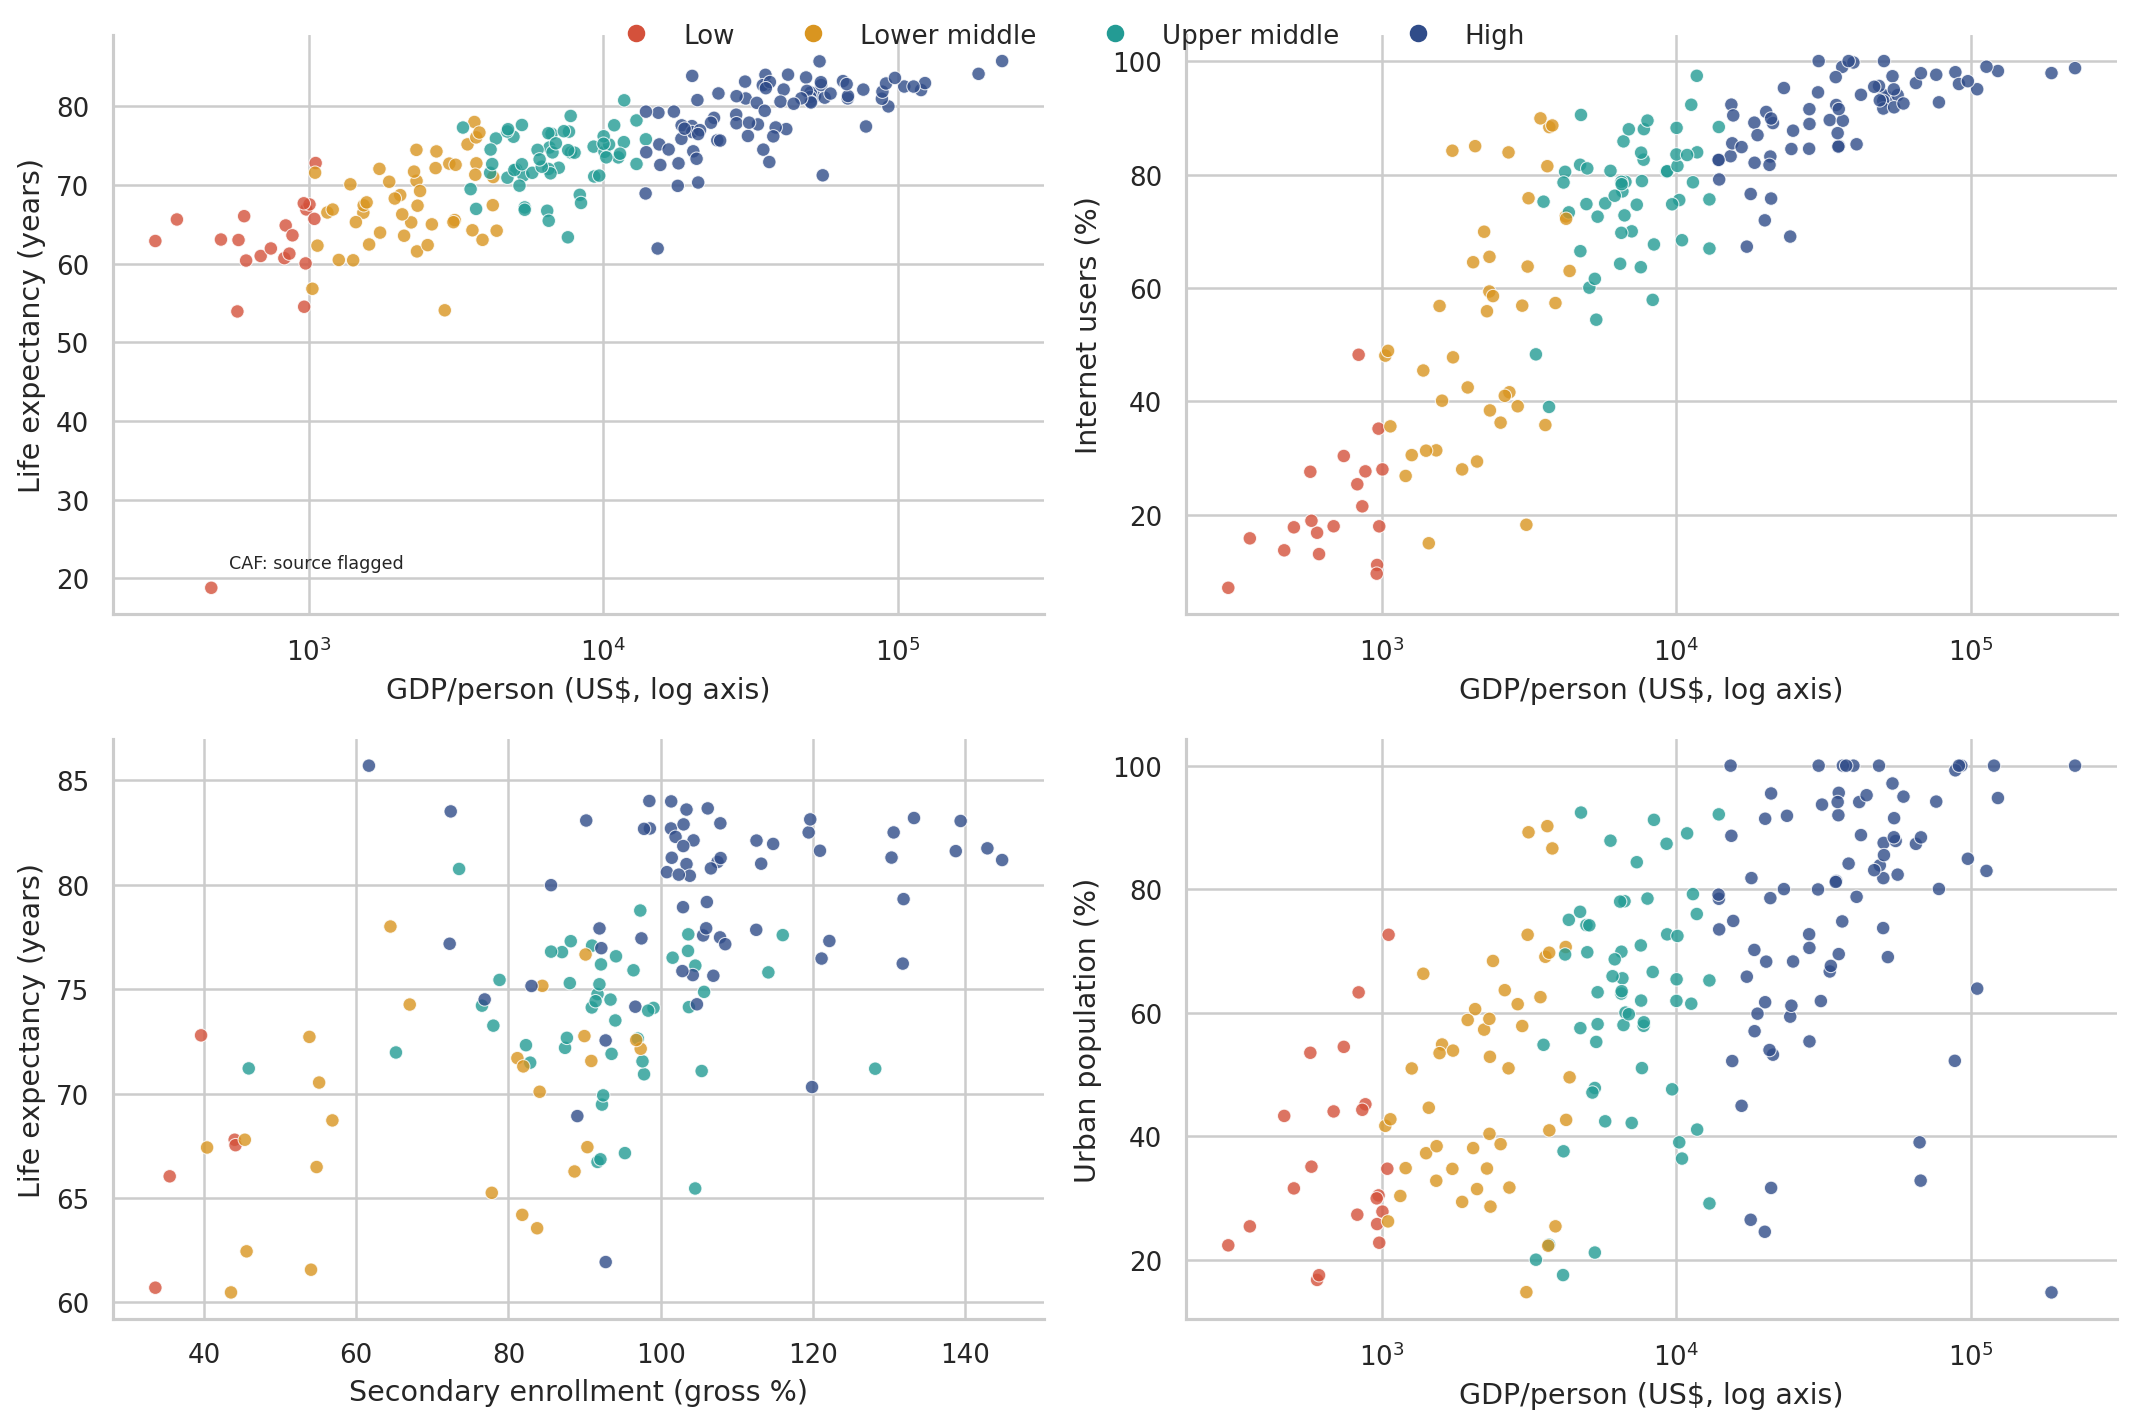

In [3]:
project.eda(state)
display(state['descriptive_statistics'].round(3))
display(state['quality_flags'])
show_figures('01_missingness', '02_required_distributions', '03_gdp_transform',
             '04_income_group_comparisons', '05_observed_correlations',
             '06_required_pairwise_relationships')


### Interpretation of the exploratory evidence

Income, longevity, connectivity and electricity tend to increase together, while countries within the same reference income group still differ. Electricity access clusters near 100% for many economies, so it has a ceiling effect. Growth and inflation include large country-specific extremes and need separate interpretation from the slower-moving development indicators.

Correlated development variables can partly repeat information; PCA provides an orthogonal representation, but it does not make feature selection or substantive interpretation automatic. Correlation does not establish a causal relationship. The source-quality observation is visible and labelled rather than silently removed from the EDA.


## 3. Numerical preprocessing and PCA

Sequence: **ln(GDP per capita) -> global median imputation -> standardization -> correlation analysis -> PCA**. Standardization uses the mean and standard deviation of the retained cross-sectional sample. The objective is descriptive clustering of this sample, not supervised prediction; train/validation/test splits from regression/classification are not imported without a prediction objective. Sensitivity runs refit every preprocessing step on their own samples.

PCA keeps the smallest number of components whose cumulative explained variance reaches 80%. This is a transparent compression rule rather than a claim that 80% is universally optimal. Coefficient tables and fitted preprocessing parameters are exported. The values called coefficients here are normalized PCA eigenvector entries, not correlations between PCs and variables.


PCA: 6 components retain 84.67%; first two retain 51.13%.
Coefficient signs are arbitrary. Large absolute coefficients identify variables defining each direction.
                        PC1    PC2    PC3
GDP_PC                0.450  0.040  0.028
GDP_Growth            0.012  0.380  0.579
Inflation            -0.074 -0.518 -0.217
Unemployment         -0.023 -0.341  0.714
Trade                 0.232 -0.043  0.033
Capital_Formation     0.009  0.651 -0.098
Life_Expectancy       0.424  0.059 -0.100
Urban_Population      0.368 -0.182  0.005
Internet_Users        0.449 -0.046 -0.037
Electricity_Access    0.404  0.030 -0.087
Secondary_Enrollment  0.238 -0.061  0.279


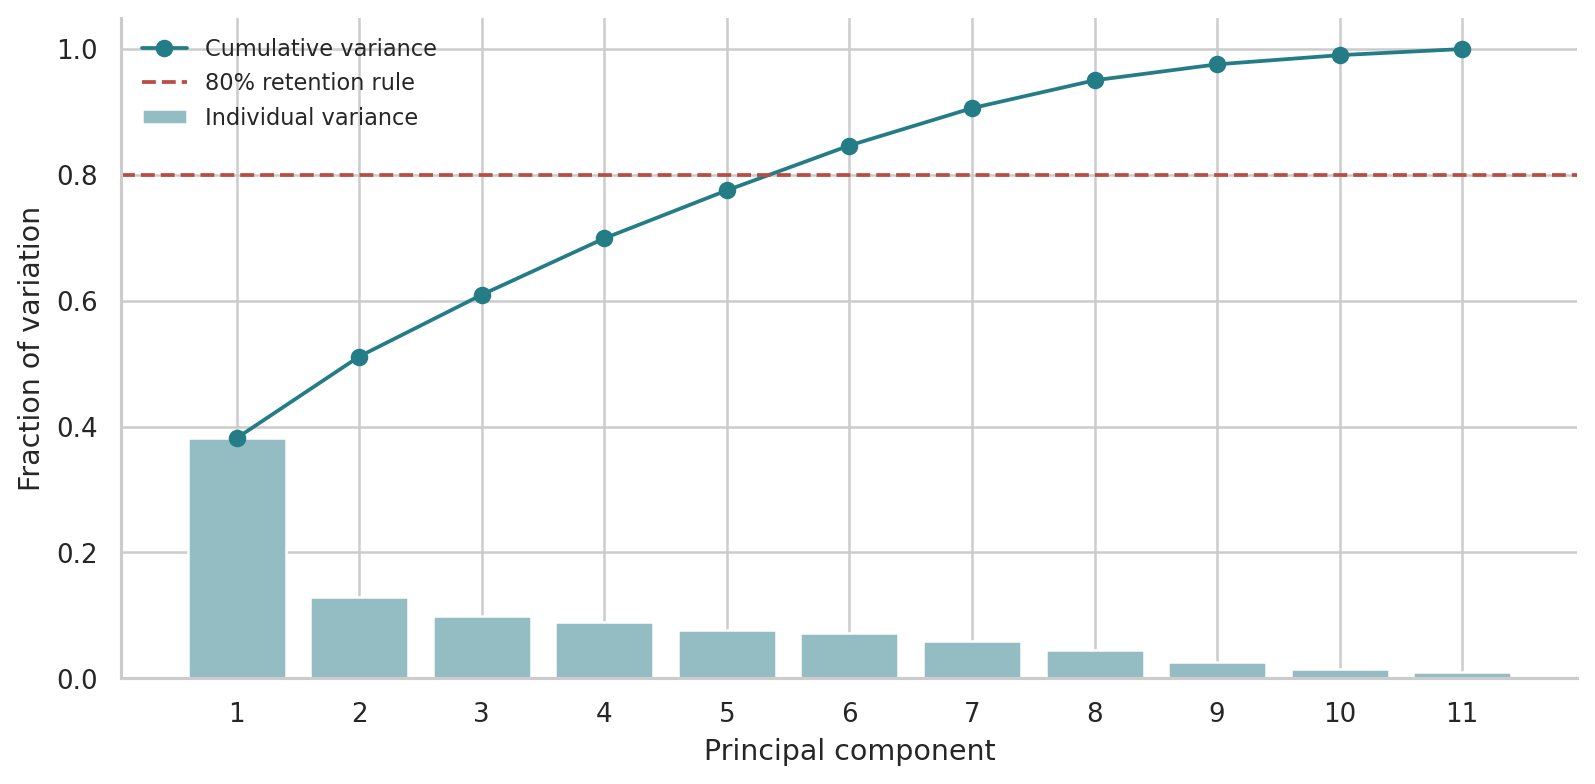

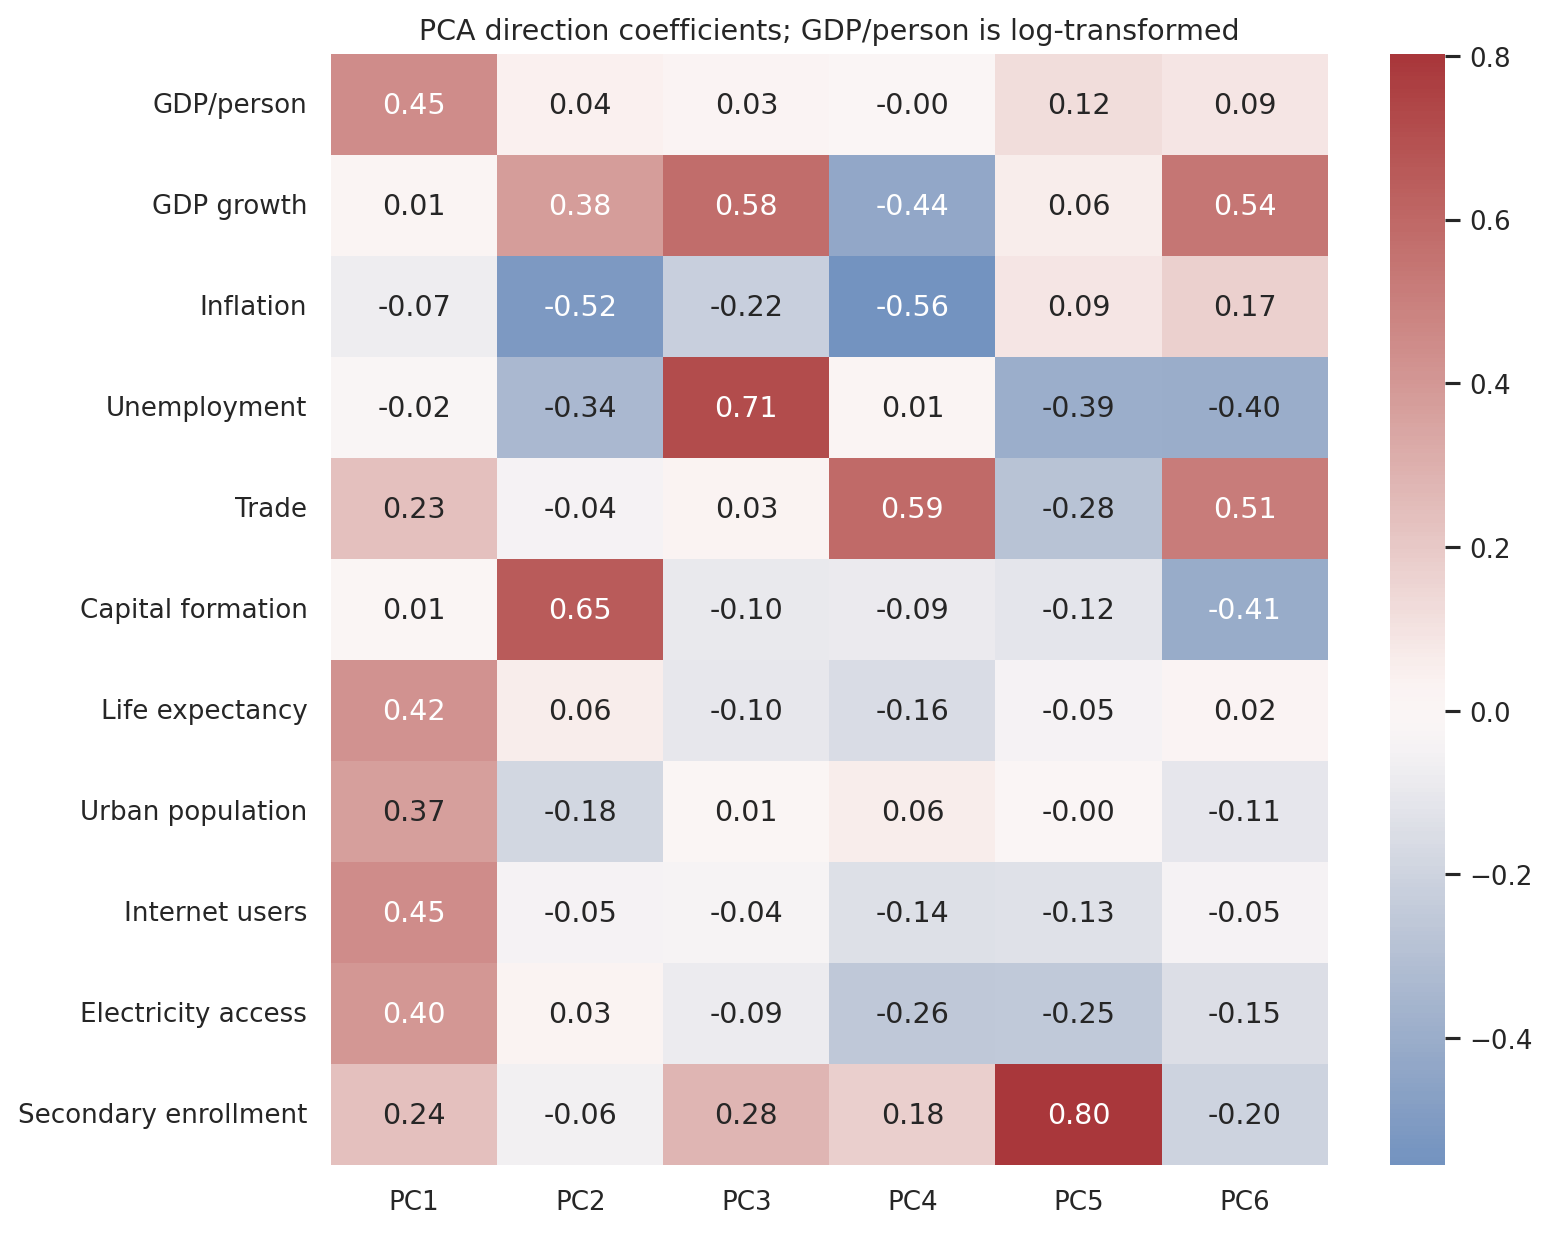

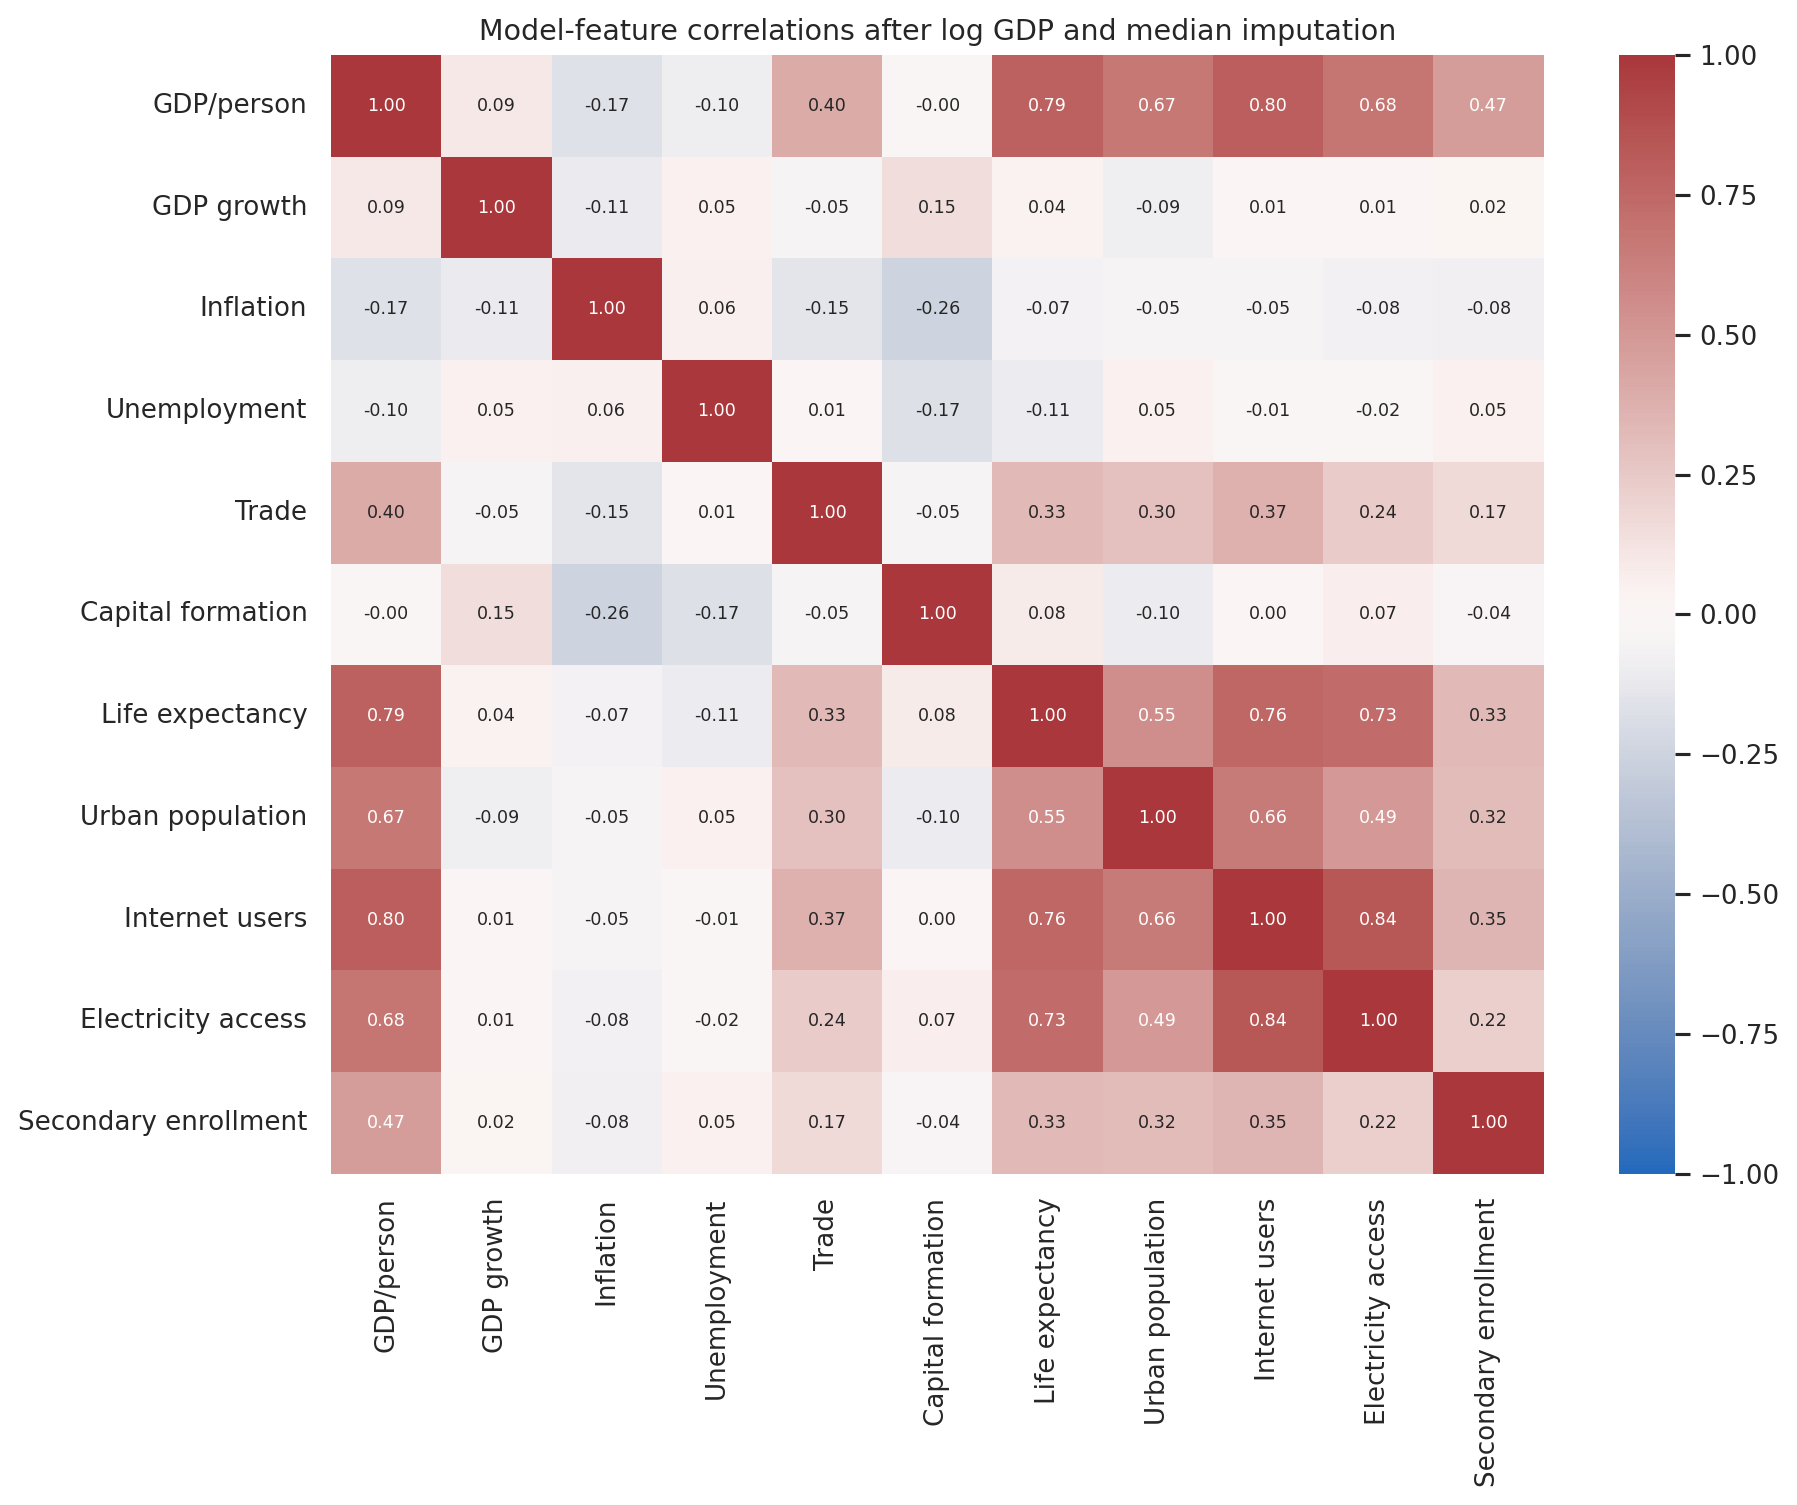

In [4]:
project.preprocess(state)
show_figures('07_pca_variance', '08_pca_coefficients', '09_model_correlations')


In [5]:
loadings = state['loadings']
for component in ['PC1', 'PC2', 'PC3']:
    print(component, 'largest absolute coefficients:')
    print(loadings[component].sort_values(key=abs, ascending=False).head(5).round(3))
display(Markdown('Interpret components from their large coefficients, signs and underlying units. '
                 'PC1 describes a broad development/infrastructure direction. '
                 'Later components distinguish macroeconomic and labour-market differences. '
                 'The sign of an entire PC can reverse without changing the solution; '
                 'these are descriptive directions, not causal or welfare rankings.'))


PC1 largest absolute coefficients:
GDP_PC                0.450
Internet_Users        0.449
Life_Expectancy       0.424
Electricity_Access    0.404
Urban_Population      0.368
Name: PC1, dtype: float64
PC2 largest absolute coefficients:
Capital_Formation    0.651
Inflation           -0.518
GDP_Growth           0.380
Unemployment        -0.341
Urban_Population    -0.182
Name: PC2, dtype: float64
PC3 largest absolute coefficients:
Unemployment            0.714
GDP_Growth              0.579
Secondary_Enrollment    0.279
Inflation              -0.217
Life_Expectancy        -0.100
Name: PC3, dtype: float64


Interpret components from their large coefficients, signs and underlying units. PC1 describes a broad development/infrastructure direction. Later components distinguish macroeconomic and labour-market differences. The sign of an entire PC can reverse without changing the solution; these are descriptive directions, not causal or welfare rankings.

### Meaning of the six retained components

In the frozen main fit, PC1 puts large coefficients on log GDP per capita, Internet usage, life expectancy and electricity access, describing a broad development/infrastructure direction. PC2 contrasts capital formation and GDP growth with inflation and unemployment. PC3 has large coefficients on unemployment and growth together; it captures a residual statistical direction, not a claim that growth causes unemployment. PC4 contrasts trade with inflation and growth. PC5 is dominated by secondary-school enrollment, with unemployment contributing in the opposite direction. PC6 contrasts growth and trade with capital formation and unemployment.

These interpretations use relative signs and magnitudes of the displayed coefficients. Flipping every coefficient in a component leaves the interpretation of its contrasts and the PCA geometry unchanged. Variance retention does not make a component a welfare index.


## 4. K-means and hierarchical clustering

K-means tests k=2 through 8 with seed 42 and 50 initializations. The primary selection rule is the largest mean silhouette score over this finite candidate range; the elbow, group sizes and interpretability provide context. We do not force four groups to match the four income categories.

Ward agglomerative clustering uses **the same preprocessed countries, retained PCA dimensions and selected k**. Ward successively merges groups with the smallest increase in within-group variance. It is included under the professor's explicit permission for hierarchical libraries. The dendrogram overview marks the chosen cut. Both models operate in six dimensions; the two-PC scatter plots are visual summaries that omit variation used by the models.


K-means selected k=2 over k=2..8 by highest silhouette; inspect sizes and elbow as context.
 k   inertia  silhouette  smallest_cluster  largest_cluster
 2 1303.8376      0.3572                60              145
 3 1128.4516      0.2140                40               94
 4  986.4319      0.2290                 3               92
 5  861.6971      0.2448                 3               76
 6  785.7718      0.2117                 3               74
 7  709.8467      0.2552                 1               76
 8  640.0624      0.2223                 1               72


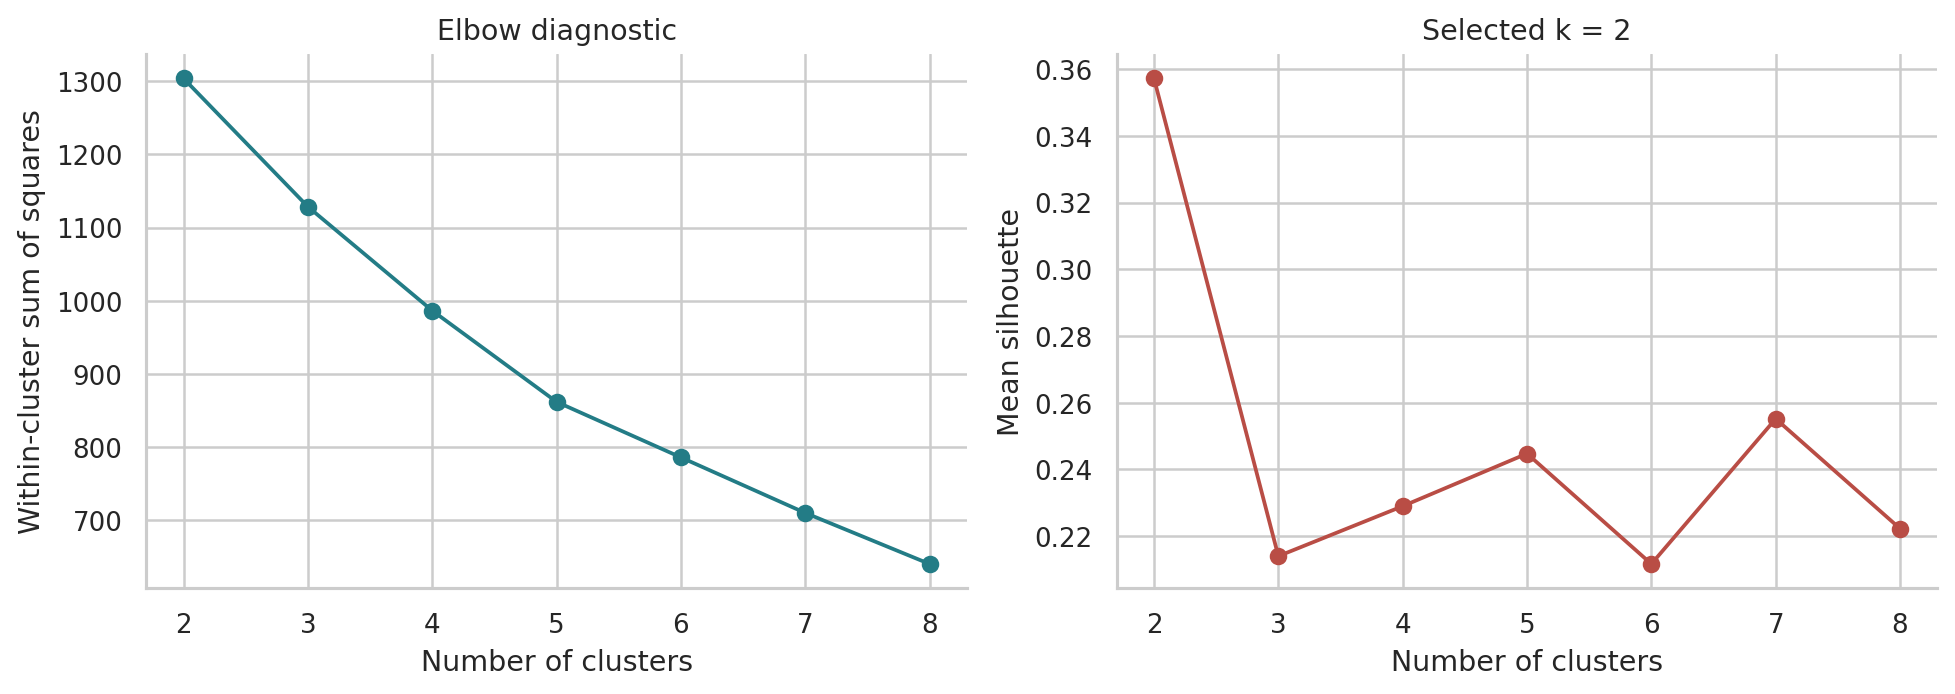

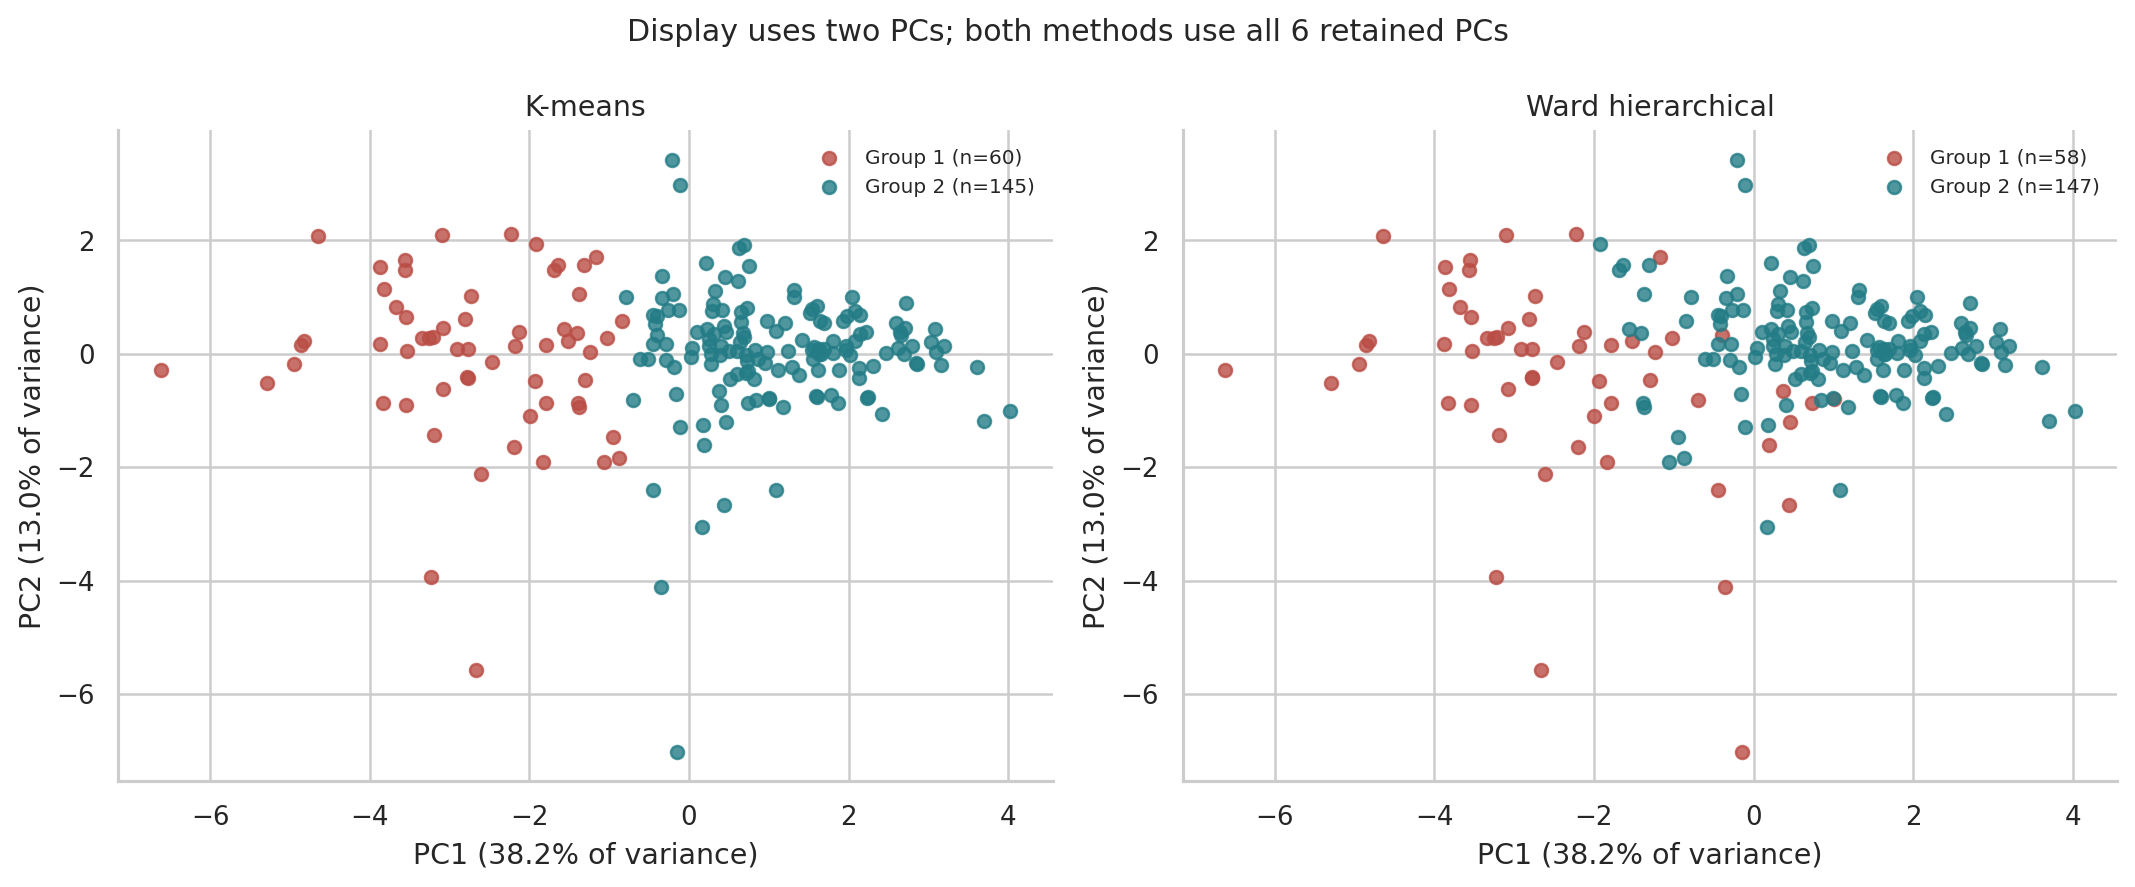

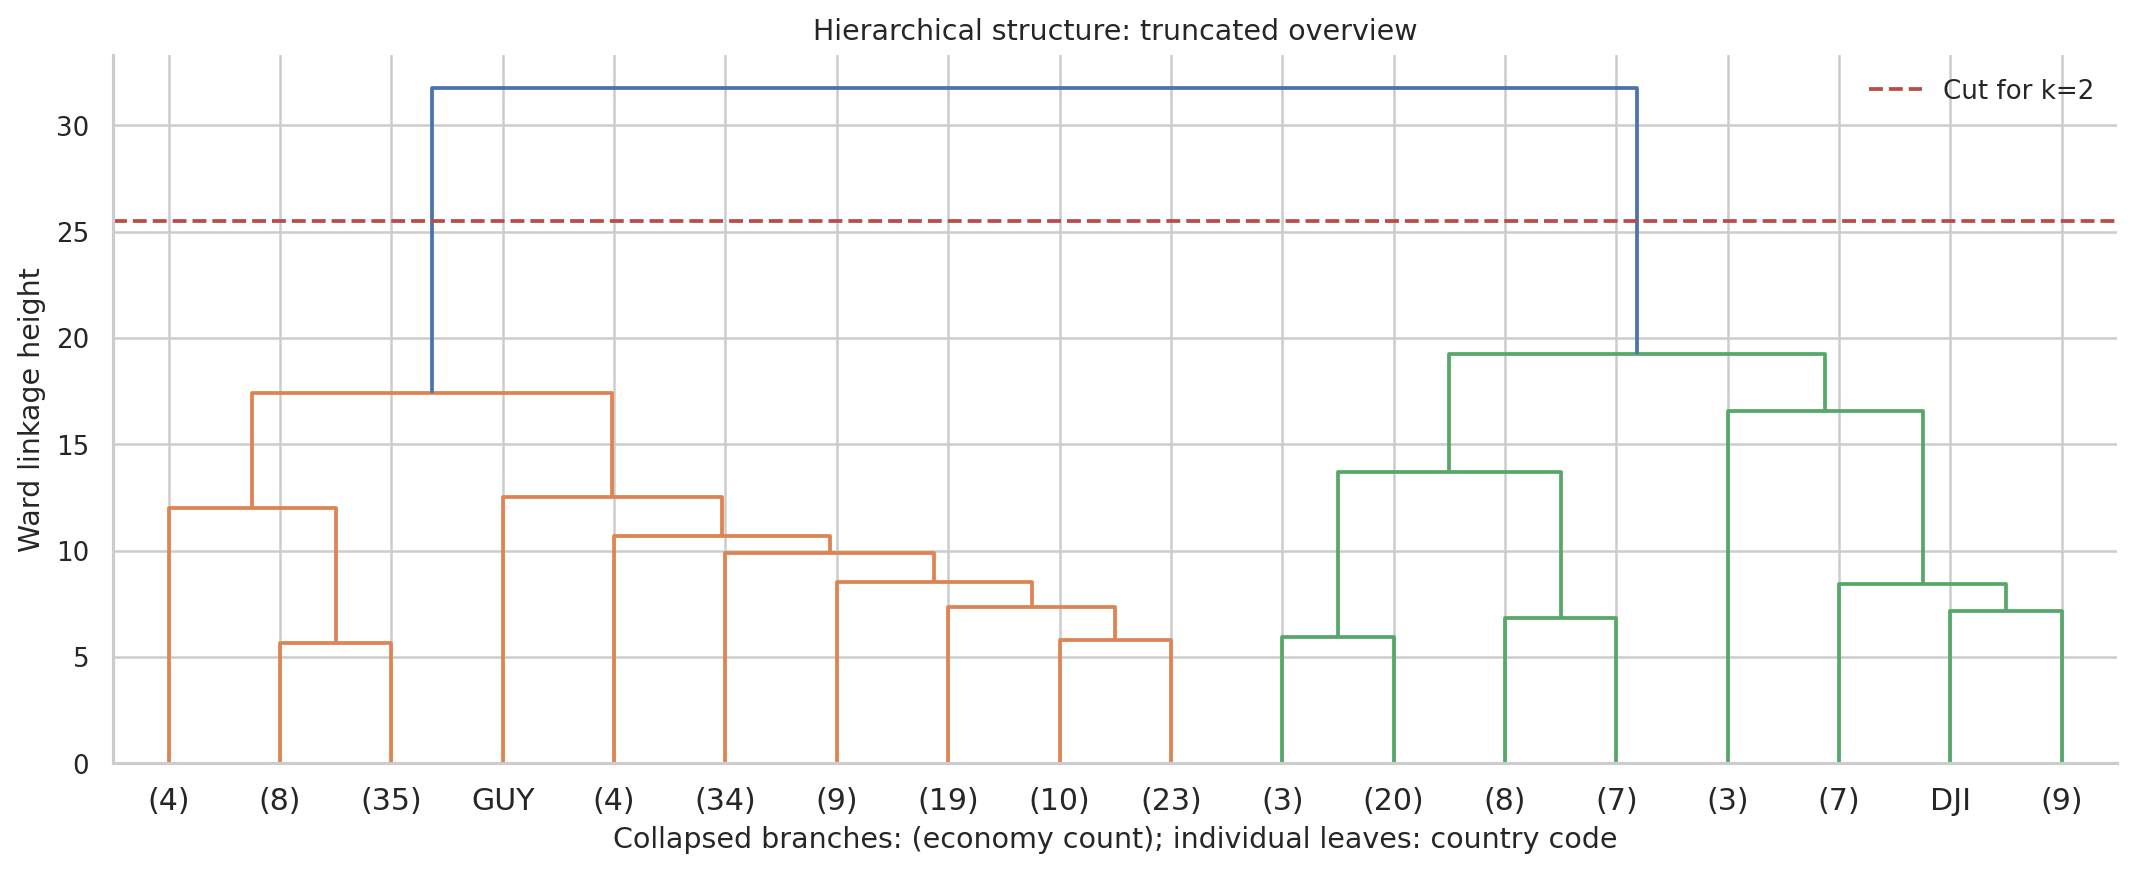

In [6]:
with threadpool_limits(limits=1):
    project.clustering(state)
show_figures('10_cluster_count_selection', '11_pca_cluster_comparison',
             '12_ward_dendrogram_overview')


## 5. Socioeconomic interpretation, external comparisons and unusual economies

Cluster numbers are names rather than ranks. For readability they are ordered by observed median GDP per capita after fitting; that naming step does not feed labels or GDP information into a model that did not use it. Describe groups using original-unit medians and observation counts as well as standardized profiles.

Income/region comparisons are counts and clearly normalized percentages. ARI/NMI compare partitions independently of arbitrary label numbering and are not classification accuracy. A difference list based on GDP-ordered names is also exported, with that naming convention explicit.

Large distance to the centroid identifies unusual profiles. Negative individual silhouette identifies ambiguity between clusters; these are distinct properties. The country table exports both, within-cluster distance percentiles, observed feature values and imputation flags. Feature deviations are descriptive in standardized original-feature space and are not an exact decomposition of PCA-space distance.


Original-unit cluster medians (observed values only; per-feature counts exported):
                  GDP_PC  GDP_Growth  Inflation  Unemployment  Trade  Capital_Formation  Life_Expectancy  Urban_Population  Internet_Users  Electricity_Access  Secondary_Enrollment
KMeans_Cluster                                                                                                                                                                      
1                1490.50        4.14       9.09          4.54  61.26              22.15            65.26             38.22           35.72               58.85                 54.97
2               15564.55        4.35       7.92          5.59  99.24              24.47            76.58             72.68           84.92              100.00                100.82
K-means versus Ward:
 Ward_Cluster     1    2
KMeans_Cluster         
1               47   13
2               11  134
ARI=0.5712; NMI=0.4212. Agreement is descriptive, not classification accura

,method,k,silhouette,sizes
0,K-means,2,0.3572,1:60; 2:145
1,Ward,2,0.3400,1:58; 2:147


Ward_Cluster,1,2
KMeans_Cluster,,
1,47,13
2,11,134


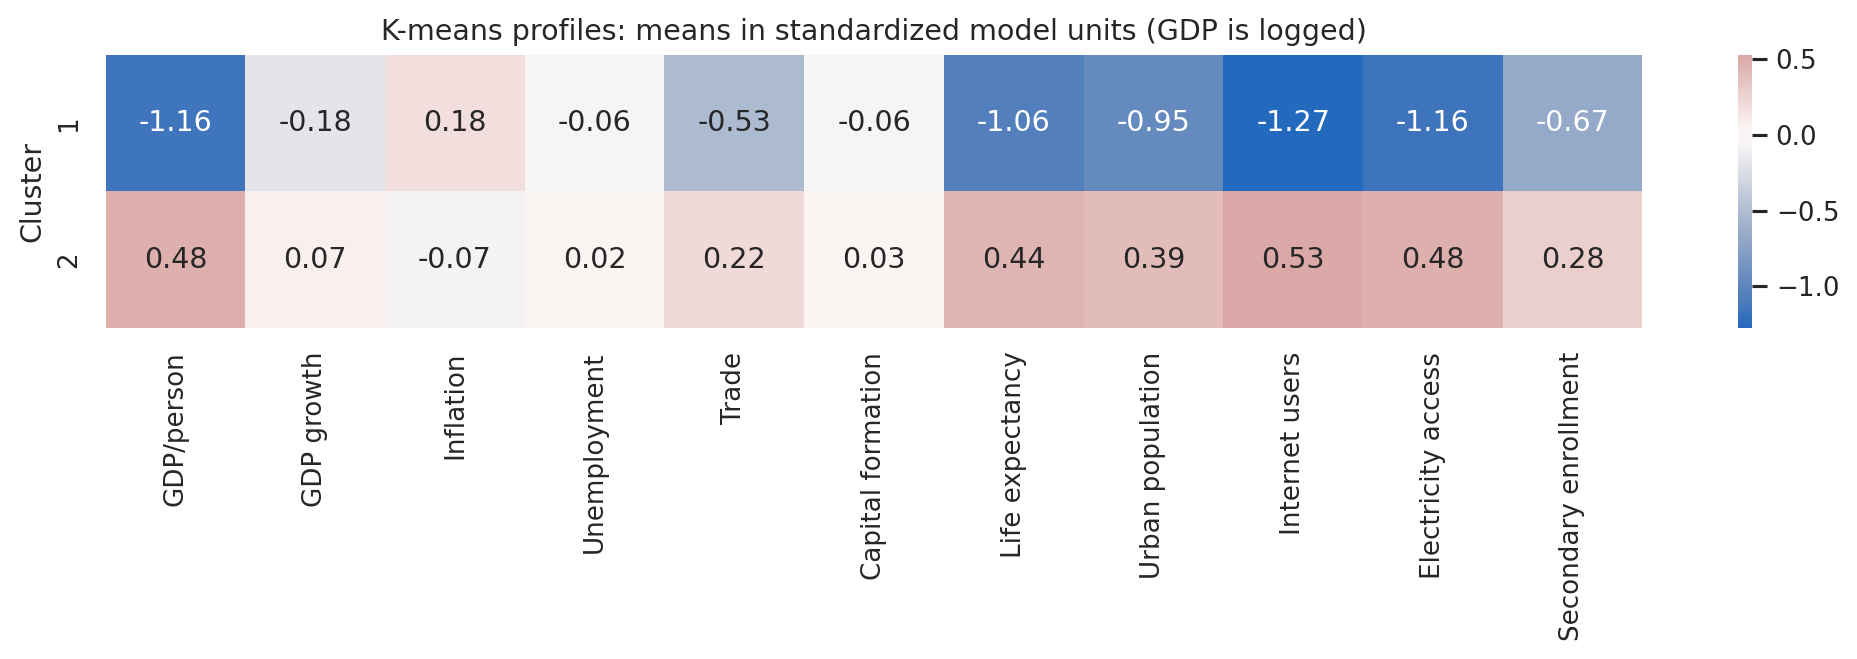

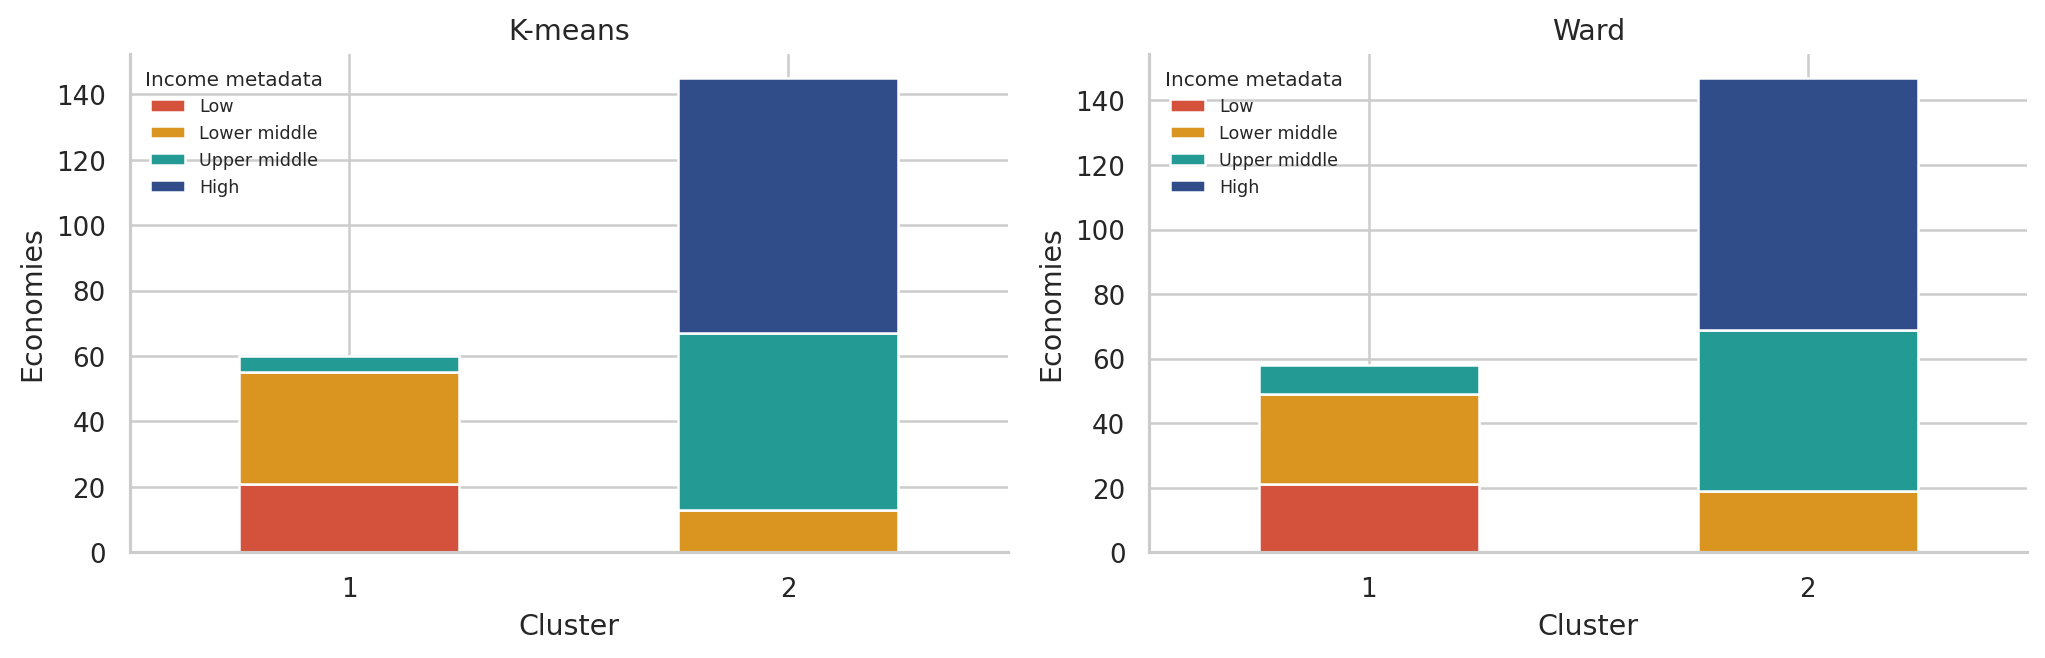

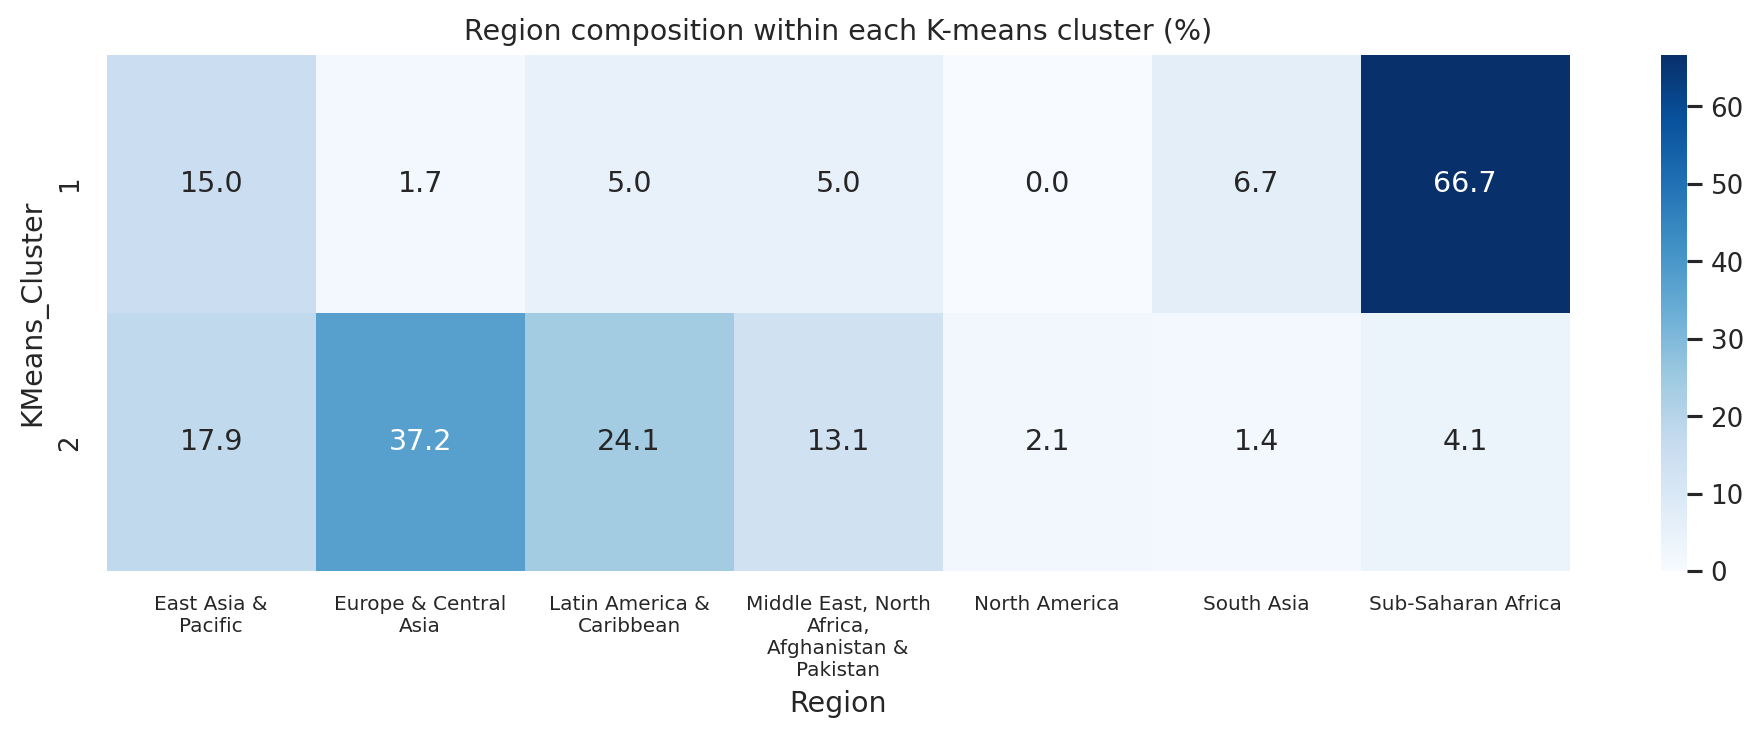

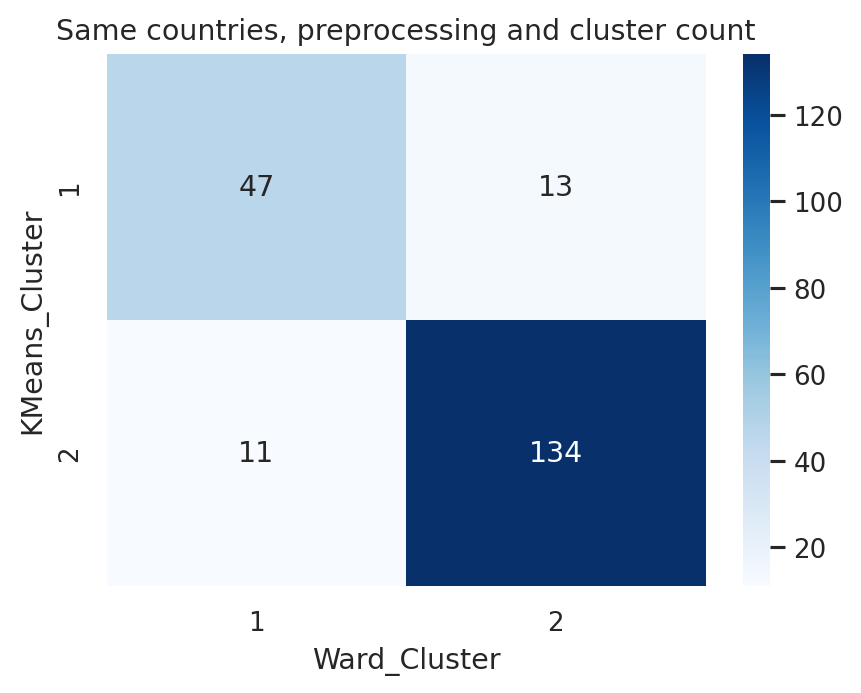

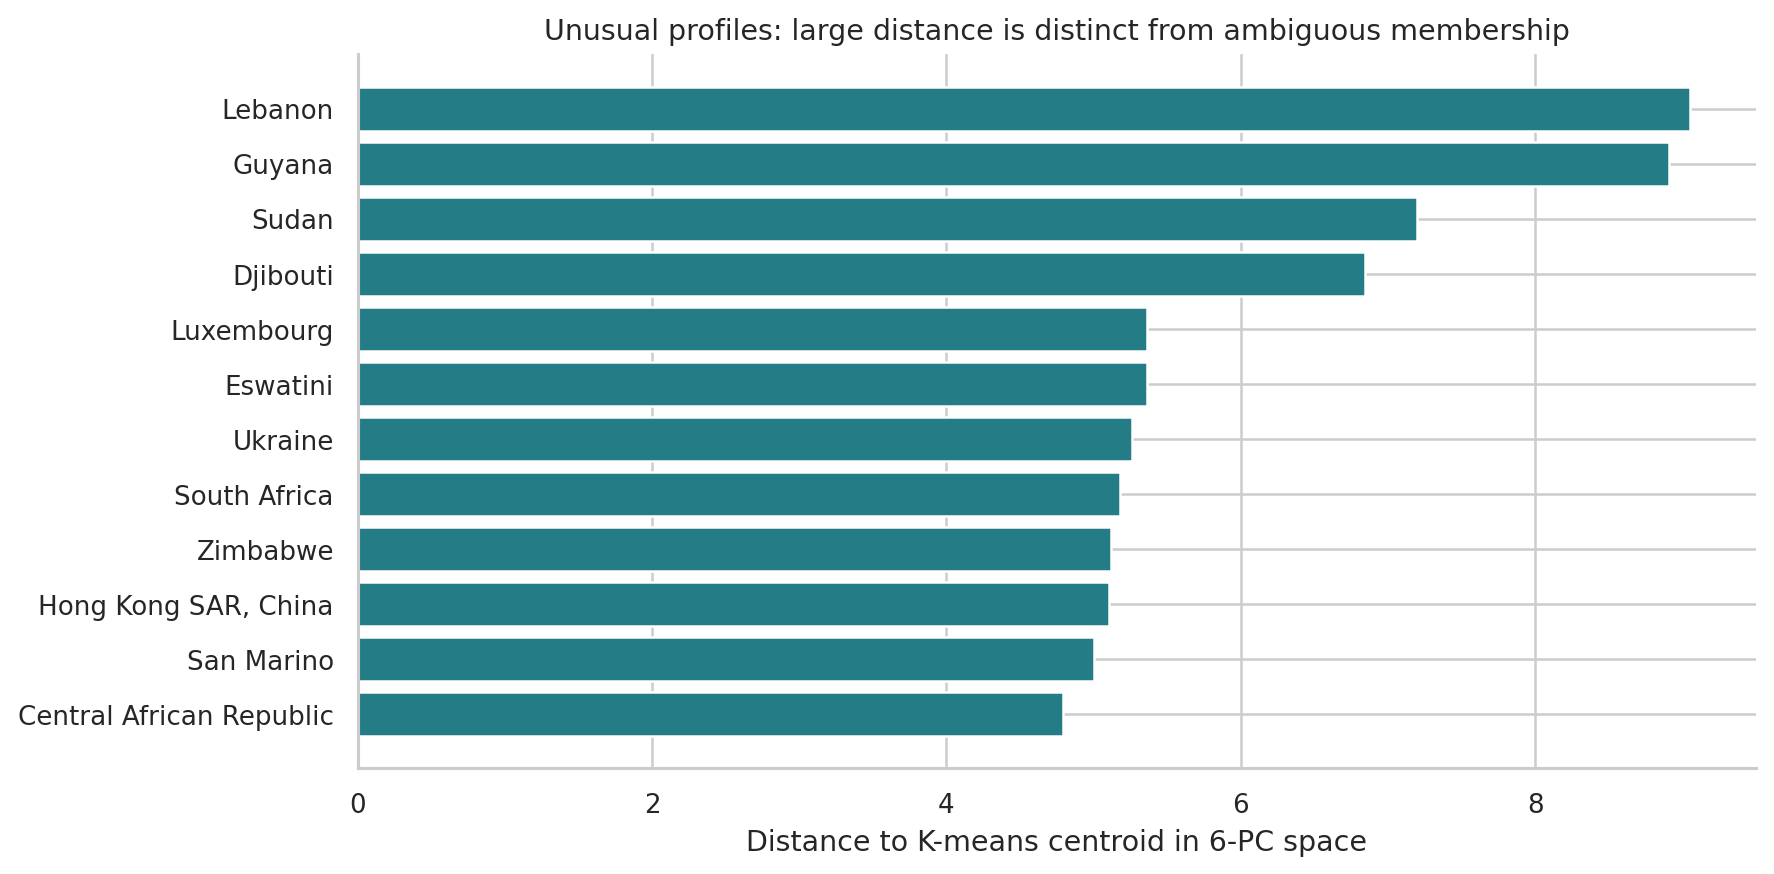

,Country Name,KMeans_Cluster,Ward_Cluster,Distance_to_Centroid,Within_Cluster_Distance_Percentile,Silhouette,Imputed_Indicators
103,Lebanon,2,1,9.047595,100.000000,0.025295,0
78,Guyana,2,2,8.910230,99.310345,0.052316,3
174,Sudan,1,1,7.197514,100.000000,0.085387,2
51,Djibouti,2,1,6.843178,98.620690,0.035097,1
108,Luxembourg,2,2,5.362871,97.931034,0.306676,0
59,Eswatini,1,1,5.361885,98.333333,0.048707,2
192,Ukraine,2,2,5.261158,97.241379,0.086125,2
168,South Africa,2,1,5.179590,96.551724,0.073292,0
204,Zimbabwe,1,1,5.117517,96.666667,0.176678,1
81,"Hong Kong SAR, China",2,2,5.102795,95.862069,0.308272,0


,Country Name,KMeans_Cluster,Ward_Cluster,Silhouette,Imputed_Indicators
57,Equatorial Guinea,1,2,-0.008582,1
184,Tonga,1,2,-0.056911,0


In [7]:
with threadpool_limits(limits=1):
    project.interpretation(state)
display(state['method_comparison'].round(4))
display(state['cross'])
show_figures('14_cluster_profiles', '15_clusters_vs_income', '16_clusters_vs_regions',
             '17_algorithm_cross_table', '18_unusual_countries')
display(state['assigned'].sort_values('Distance_to_Centroid', ascending=False)
        [['Country Name', 'KMeans_Cluster', 'Ward_Cluster', 'Distance_to_Centroid',
          'Within_Cluster_Distance_Percentile', 'Silhouette', 'Imputed_Indicators']].head(12))
display(state['assigned'].loc[state['assigned'].Silhouette < 0,
        ['Country Name', 'KMeans_Cluster', 'Ward_Cluster', 'Silhouette', 'Imputed_Indicators']])


### Interpreting the country cases

Lebanon's source measurements combine very high inflation and low capital formation. Guyana has exceptionally high GDP growth. Sudan has high inflation, while Luxembourg has high trade relative to GDP. These measurements explain why their profiles deserve inspection; causal stories would require separate evidence. The exported country-driver table identifies the largest observed deviations from the assigned cluster's standardized profile.

Imputed values must not be presented as measured facts. For example, Guyana has several missing indicators and Monaco has five. Use the individual flags and original-unit counts when drawing conclusions.


## 6. Robustness and comparison with the original baseline

The diagnostics assess raw versus logged GDP, full standardized features, 90%-variance PCA, a stricter missingness rule, complete cases, a three-group cut, removal of GDP, and exclusion of the source-quality flag. They reuse the same permitted clustering algorithms. The GDP-removal experiment is only a diagnostic; the primary model keeps all 11 required indicators. Each diagnostic refits its imputer, scaler and PCA.

Ten random seeds assess initialization sensitivity with 50 starts per seed. This does not establish stability to every source of sampling or modeling uncertainty. Comparisons with the primary partition use common economies only.

**Silhouettes in different feature spaces or samples are not directly ranked as universal model quality.** Transformations are justified by distributional properties and interpretation, rather than by maximizing agreement with known income groups or between algorithms.


In [8]:
with threadpool_limits(limits=1):
    project.robustness(state)
display(state['robustness'].round(4))
display(state['seeds'].round(5))


ROBUSTNESS (silhouettes from different spaces/samples are not directly ranked):
               configuration   n  dimensions  k  silhouette_in_own_space  ARI_vs_main_common_countries  ARI_KMeans_vs_Ward KMeans_sizes Ward_sizes
      Main: log GDP, PCA 80% 205           6  2                   0.3572                        1.0000              0.5712       60;145     58;147
            Raw GDP baseline 205           6  2                   0.3235                        0.9799              0.0801       61;144     130;75
  Log GDP, no PCA truncation 205          11  2                   0.3091                        1.0000              0.7547       60;145     61;144
            Log GDP, PCA 90% 205           7  2                   0.3361                        1.0000              0.5476       60;145     70;135
  Log GDP, at most 3 missing 190           6  2                   0.3458                        0.9786              0.4306       60;130     30;160
     Log GDP, complete cases 110      

,configuration,n,dimensions,k,silhouette_in_own_space,ARI_vs_main_common_countries,ARI_KMeans_vs_Ward,KMeans_sizes,Ward_sizes
0,"Main: log GDP, PCA 80%",205,6,2,0.3572,1.0000,0.5712,60;145,58;147
1,Raw GDP baseline,205,6,2,0.3235,0.9799,0.0801,61;144,130;75
2,"Log GDP, no PCA truncation",205,11,2,0.3091,1.0000,0.7547,60;145,61;144
3,"Log GDP, PCA 90%",205,7,2,0.3361,1.0000,0.5476,60;145,70;135
4,"Log GDP, at most 3 missing",190,6,2,0.3458,0.9786,0.4306,60;130,30;160
5,"Log GDP, complete cases",110,5,2,0.3583,0.6997,0.1837,28;82,59;51
6,"Log GDP, PCA 80%, k=3",205,6,3,0.2140,0.3106,0.2784,40;94;71,38;20;147
7,GDP omitted diagnostic,205,6,2,0.3409,0.9799,0.2902,59;146,106;99
8,Source-quality flag excluded,204,6,2,0.3572,0.9798,0.5860,60;144,59;145


,seed,ARI_vs_main,silhouette
0,0,1.0,0.35718
1,1,1.0,0.35718
2,2,1.0,0.35718
3,3,1.0,0.35718
4,4,1.0,0.35718
5,5,1.0,0.35718
6,6,1.0,0.35718
7,7,1.0,0.35718
8,8,1.0,0.35718
9,9,1.0,0.35718


## 7. Structural validation and exported results

The run verifies finite inputs, scaling, PCA retention, country-row alignment, cluster counts and held-out metadata. The additional test script also changes all metadata labels and checks that neither preprocessing nor clustering changes. It verifies both the main result and the original teammate baseline against the frozen snapshot.

Run `python tests/check_results.py` after the analysis. Results, figures, source-quality flags, exclusions, fitted parameters, alternative assignments and comparison tables are in the package. `CODE_REQUIREMENTS_CHECKLIST.md` maps assignment tasks to actual code outputs.


In [9]:
summary = project.validate_and_save(state)
display(Markdown(f"**Completed:** {summary['counts']['retained']} economies; "
                 f"{summary['n_components']} PCs retain {summary['retained_variance']:.2%} of variance; "
                 f"selected k={summary['selected_k']}."))
display(Markdown(f"K-means silhouette = {summary['kmeans_silhouette']:.3f}; "
                 f"Ward silhouette = {summary['ward_silhouette']:.3f}; "
                 f"between-method ARI = {summary['ari_between_methods']:.3f}."))


All structural checks passed. Results written to outputs/results.json.
{
  "configuration": {
    "year": 2022,
    "missing_fraction_max": 0.5,
    "log_gdp": true,
    "pca_variance_target": 0.8,
    "k_values": [
      2,
      3,
      4,
      5,
      6,
      7,
      8
    ],
    "random_state": 42,
    "n_init": 50,
    "hierarchical_linkage": "ward"
  },
  "counts": {
    "wdi_entities": 266,
    "metadata_economies": 217,
    "matched_economies": 217,
    "excluded": 12,
    "retained": 205,
    "complete_cases": 110
  },
  "features": [
    "GDP_PC",
    "GDP_Growth",
    "Inflation",
    "Unemployment",
    "Trade",
    "Capital_Formation",
    "Life_Expectancy",
    "Urban_Population",
    "Internet_Users",
    "Electricity_Access",
    "Secondary_Enrollment"
  ],
  "metadata": "Retrieved from official Country API on 2026-11-23",
  "n_components": 6,
  "retained_variance": 0.8466687625015747,
  "first_two_variance": 0.5112620845597924,
  "selected_k": 2,
  "kmeans_sizes":

**Completed:** 205 economies; 6 PCs retain 84.67% of variance; selected k=2.

K-means silhouette = 0.357; Ward silhouette = 0.340; between-method ARI = 0.571.

### Quantified interpretation of the final groups

The observed median GDP per capita is US$1,491 in group 1 and US$15,565 in group 2. Corresponding median life expectancies are 65.3 and 76.6 years; median Internet usage is 35.7% and 84.9%. These are observed-only medians, with feature-specific counts exported. Group 1 describes lower average development/infrastructure measurements and group 2 higher measurements, while macroeconomic exceptions remain.

All 21 retained economies labelled low income fall in group 1, and all 78 labelled high income fall in group 2. Middle-income economies span both groups: in particular, 13 lower-middle-income economies belong to group 2. These are comparisons with the 2026 metadata snapshot, not historical 2022 classifications.

The GDP-ordered K-means and Ward groupings disagree for 24 of 205 economies. The country list identifies them; the two algorithms produce similar broad structure but do not reproduce an identical partition.

The GDP-omission diagnostic has ARI 0.980 against the primary K-means grouping, indicating that the other ten features reproduce almost the same broad split. Excluding the source-quality flagged economy yields ARI 0.980 on common economies. These checks limit the claim that the observed split is solely a raw-income artifact or solely a consequence of that one questionable value; they do not establish a unique natural partition.


## Conclusions and limits

The numerical sample supports a broad socioeconomic split associated with infrastructure, connectivity, health and income. The two groups remain descriptive summaries, with overlapping country profiles and macroeconomic exceptions. The robustness table establishes which assignments persist and which depend on preprocessing, exclusions or cluster count; it does not turn one algorithm into ground truth.

The current-income comparison is temporally different from a historical 2022 classification. Missing data and source anomalies limit country-specific claims. Global median imputation compresses variation, correlated indicators affect the distance geometry, and retaining high-variance PCs can omit substantively interesting differences. Economies are weighted equally, not by population, and the one-year study cannot establish causal effects or development trajectories.

### Sources and method documentation

- WDI: https://datatopics.worldbank.org/world-development-indicators/
- Indicator IDs and retrieval URLs: `data/provenance.json` and `INDICATORS` in `analysis.py`.
- Country metadata: https://api.worldbank.org/v2/country?format=json&per_page=400
- Source-quality point-series check: `DATA_QUALITY.md` and `data/quality_checks/`.
- scikit-learn clustering: https://scikit-learn.org/stable/modules/clustering.html
- PCA: https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html
- The original supplied implementation is preserved in `reference/teammate_PCA_original.ipynb`.
